In [9]:
import numpy as np
import pandas as pd
from datetime import datetime, timedelta

# Set random seed for consistent, reproducible results
np.random.seed(42)

# ==========================================
# 1. MAIN TIME-SERIES & EXPLORATORY DATASET
# (For: Line, Scatter, Hist, Boxplot, ECDF, Pairplot, Heatmap, Hexbin, Dual-Axes, Insets)
# ==========================================
n_days = 365
dates = pd.date_range(start="2025-01-01", periods=n_days, freq="D")

# Generate realistic continuous variables with correlations and trend components
trend = np.linspace(10, 50, n_days)
seasonality = 15 * np.sin(np.linspace(0, 4 * np.pi, n_days))
noise = np.random.normal(0, 5, n_days)

ad_spend = np.random.uniform(500, 5000, n_days)
website_traffic = (ad_spend * 1.5) + np.random.normal(2000, 500, n_days)
conversion_rate = np.clip(np.random.normal(0.035, 0.008, n_days), 0.01, 0.08)
units_sold = (website_traffic * conversion_rate).astype(int)
unit_price = np.random.choice([49.99, 99.99, 149.99], size=n_days, p=[0.5, 0.3, 0.2])

revenue = units_sold * unit_price + trend + seasonality
expenses = (revenue * 0.55) + (ad_spend * 0.8) + noise
profit = revenue - expenses
csat_score = np.clip(np.random.normal(4.2, 0.4, n_days), 1.0, 5.0)

# Categorical columns
regions = np.random.choice(["North America", "Europe", "Asia-Pacific", "LATAM"], size=n_days, p=[0.4, 0.3, 0.2, 0.1])
categories = np.random.choice(["Software", "Hardware", "Services"], size=n_days, p=[0.5, 0.3, 0.2])
customer_segments = np.random.choice(["Enterprise", "Mid-Market", "SMB"], size=n_days, p=[0.2, 0.35, 0.45])

df_main = pd.DataFrame({
    "date": dates,
    "revenue": np.round(revenue, 2),
    "expenses": np.round(expenses, 2),
    "profit": np.round(profit, 2),
    "units_sold": units_sold,
    "website_traffic": np.round(website_traffic).astype(int),
    "conversion_rate": np.round(conversion_rate, 4),
    "ad_spend": np.round(ad_spend, 2),
    "csat_score": np.round(csat_score, 2),
    "region": regions,
    "category": categories,
    "customer_segment": customer_segments
})


# ==========================================
# 2. FINANCIAL WATERFALL DATASET
# (For: Waterfall Chart)
# ==========================================
df_waterfall = pd.DataFrame({
    "category": ["Starting Cash", "Product Sales", "Services Revenue", "COGS", "Marketing", "Payroll", "Taxes", "Net Ending"],
    "amount": [100000, 45000, 18000, -22000, -15000, -32000, -8000, 86000],
    "type": ["absolute", "relative", "relative", "relative", "relative", "relative", "relative", "total"]
})


# ==========================================
# 3. SALES PIPELINE FUNNEL DATASET
# (For: Conversion Funnel Chart)
# ==========================================
df_funnel = pd.DataFrame({
    "stage": ["1. Ad Impressions", "2. Website Visits", "3. Lead Signups", "4. Product Demos", "5. Closed Deals"],
    "count": [250000, 45000, 12000, 3200, 850]
})
df_funnel["conversion_pct"] = np.round((df_funnel["count"] / df_funnel["count"].iloc[0]) * 100, 2)


# ==========================================
# 4. KPI BULLET CHART DATASET
# (For: Bullet Chart)
# ==========================================
df_bullet = pd.DataFrame({
    "metric": ["Revenue ($k)", "New Customers", "CSAT Score", "Uptime (%)"],
    "actual": [275, 1400, 4.4, 99.8],
    "target": [300, 1500, 4.5, 99.9],
    "poor": [150, 800, 3.0, 95.0],
    "satisfactory": [250, 1200, 4.0, 98.0],
    "good": [350, 1800, 5.0, 100.0]
})


# ==========================================
# 5. GANTT & PROJECT TIMELINE DATASET
# (For: Gantt Chart / Timeline)
# ==========================================
df_gantt = pd.DataFrame({
    "task": ["Requirements", "Architecture Design", "Frontend Dev", "Backend Dev", "QA Testing", "Deployment"],
    "start_day": [0, 10, 25, 20, 50, 65],
    "duration": [12, 18, 30, 35, 18, 7],
    "department": ["Product", "Engineering", "Frontend", "Backend", "QA", "DevOps"]
})


# ==========================================
# 6. COHORT RETENTION MATRIX DATASET
# (For: Cohort Heatmap)
# ==========================================
cohort_months = ["Jan 2025", "Feb 2025", "Mar 2025", "Apr 2025", "May 2025", "Jun 2025"]
retention_data = np.array([
    [100, 68, 55, 48, 42, 39],
    [100, 71, 58, 50, 44, np.nan],
    [100, 65, 52, 45, np.nan, np.nan],
    [100, 74, 61, np.nan, np.nan, np.nan],
    [100, 69, np.nan, np.nan, np.nan, np.nan],
    [100, np.nan, np.nan, np.nan, np.nan, np.nan]
])
df_cohort = pd.DataFrame(retention_data, index=cohort_months, columns=[f"Month {i}" for i in range(6)])


# ==========================================
# 7. SANKEY FLOW DATASET
# (For: Sankey Diagram)
# ==========================================
df_sankey = pd.DataFrame({
    "source": ["Organic Search", "Paid Ads", "Direct Traffic", "Signups", "Signups", "Free Trial"],
    "target": ["Signups", "Signups", "Bounce", "Free Trial", "Bounce", "Paid Subscriber"],
    "value": [1200, 2300, 800, 2800, 700, 1900]
})


# ==========================================
# 8. MULTI-ATTRIBUTE RADAR DATASET
# (For: Radar / Spider Chart)
# ==========================================
df_radar = pd.DataFrame({
    "attribute": ["Price", "Performance", "UI/UX", "Customer Support", "Security", "Scalability"],
    "Product_Alpha": [4.2, 4.8, 3.5, 4.0, 4.9, 4.7],
    "Product_Beta": [4.8, 3.2, 4.6, 4.5, 3.8, 3.4]
})


# ==========================================
# 9. TWO-POINT COMPARISON DATASET
# (For: Dumbbell & Slope Charts)
# ==========================================
df_comparison = pd.DataFrame({
    "category": ["Customer Support", "Product Engineering", "Marketing", "Sales", "Operations", "HR"],
    "val_2024": [45, 120, 85, 95, 60, 30],
    "val_2025": [70, 160, 90, 130, 55, 40]
})


# ==========================================
# 10. SPATIAL & CHOROPLETH DATASET
# (For: Choropleth Maps)
# ==========================================
df_geo = pd.DataFrame({
    "state_code": ["CA", "TX", "NY", "FL", "IL", "PA", "OH", "GA", "NC", "MI"],
    "state_name": ["California", "Texas", "New York", "Florida", "Illinois", "Pennsylvania", "Ohio", "Georgia", "North Carolina", "Michigan"],
    "sales_volume": [485000, 390000, 410000, 310000, 220000, 195000, 175000, 210000, 185000, 160000],
    "latitude": [36.7783, 31.9686, 40.7128, 27.6648, 40.6331, 41.2033, 40.4173, 32.1656, 35.7596, 44.3148],
    "longitude": [-119.4179, -99.9018, -74.0060, -81.5158, -89.3985, -77.1945, -82.9071, -82.9001, -79.0193, -85.6024]
})


# ==========================================
# 11. HIERARCHICAL TREEMAP DATASET
# (For: Treemap & Waffle Charts)
# ==========================================
df_treemap = pd.DataFrame({
    "department": ["Engineering", "Engineering", "Engineering", "Sales", "Sales", "Marketing", "Marketing", "Product"],
    "sub_team": ["Backend", "Frontend", "DevOps", "Enterprise", "SMB", "Digital Ads", "Events", "Design"],
    "budget_k": [450, 320, 180, 500, 250, 300, 150, 200],
    "headcount": [18, 14, 6, 20, 12, 8, 4, 7]
})

# Summary verification
print("Datasets successfully created:")
print(f"1. df_main        : {df_main.shape} (Time Series, EDA, Distributions, Correlations)")
print(f"2. df_waterfall   : {df_waterfall.shape} (Financial Bridges)")
print(f"3. df_funnel      : {df_funnel.shape} (Conversion Pipelines)")
print(f"4. df_bullet      : {df_bullet.shape} (KPI Targets & Performance Bands)")
print(f"5. df_gantt       : {df_gantt.shape} (Project Timelines)")
print(f"6. df_cohort      : {df_cohort.shape} (Cohort Retention Matrix)")
print(f"7. df_sankey      : {df_sankey.shape} (Flow Distributions)")
print(f"8. df_radar       : {df_radar.shape} (Multi-attribute Benchmarks)")
print(f"9. df_comparison : {df_comparison.shape} (Dumbbell & Slope Comparisons)")
print(f"10. df_geo        : {df_geo.shape} (Spatial Maps)")
print(f"11. df_treemap    : {df_treemap.shape} (Hierarchical Categories)")

Datasets successfully created:
1. df_main        : (365, 12) (Time Series, EDA, Distributions, Correlations)
2. df_waterfall   : (8, 3) (Financial Bridges)
3. df_funnel      : (5, 3) (Conversion Pipelines)
4. df_bullet      : (4, 6) (KPI Targets & Performance Bands)
5. df_gantt       : (6, 4) (Project Timelines)
6. df_cohort      : (6, 6) (Cohort Retention Matrix)
7. df_sankey      : (6, 3) (Flow Distributions)
8. df_radar       : (6, 3) (Multi-attribute Benchmarks)
9. df_comparison : (6, 3) (Dumbbell & Slope Comparisons)
10. df_geo        : (10, 5) (Spatial Maps)
11. df_treemap    : (8, 4) (Hierarchical Categories)


# 01. **Relational & Trend Analysis**
## 01.01. **Line Chart** (`ax.plot`)
— Time-series trends, financial tracking, and continuous sequence metrics.

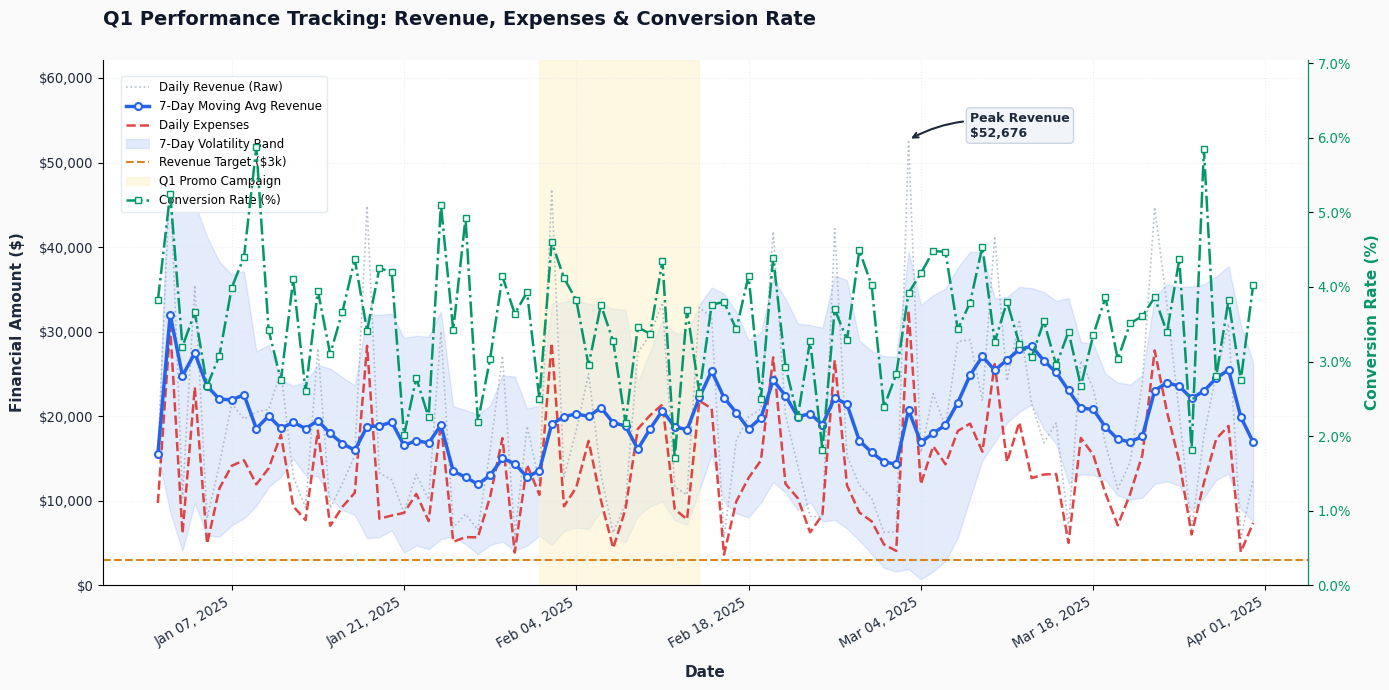

In [10]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import pandas as pd

# ---------------------------------------------------------
# Data Preparation (Subsetting 90 days for crisp visual clarity)
# ---------------------------------------------------------
df_plot = df_main.iloc[:90].copy()
df_plot["revenue_7d_avg"] = df_plot["revenue"].rolling(window=7, min_periods=1).mean()
df_plot["revenue_std"] = df_plot["revenue"].rolling(window=7, min_periods=1).std().fillna(0)

# ---------------------------------------------------------
# Figure & Axes Setup
# ---------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(14, 7), dpi=100)
fig.patch.set_facecolor("#FAFAFA")
ax1.set_facecolor("#FFFFFF")

# ---------------------------------------------------------
# Primary Axis (ax1): Revenue & Expense Metrics
# ---------------------------------------------------------
# 1. Raw Daily Data (Thin, semi-transparent line)
line1 = ax1.plot(
    df_plot["date"], df_plot["revenue"],
    color="#94A3B8", linestyle=":", linewidth=1.2, alpha=0.7,
    label="Daily Revenue (Raw)"
)

# 2. Smooth Trend Line (Primary emphasis: bold, custom markers)
line2 = ax1.plot(
    df_plot["date"], df_plot["revenue_7d_avg"],
    color="#2563EB", linestyle="-", linewidth=2.5,
    marker="o", markersize=5, markerfacecolor="#EFF6FF", markeredgecolor="#2563EB", markeredgewidth=1.5,
    label="7-Day Moving Avg Revenue", zorder=4
)

# 3. Secondary Metric Line (Dashed comparison series)
line3 = ax1.plot(
    df_plot["date"], df_plot["expenses"],
    color="#DC2626", linestyle="--", linewidth=1.8, alpha=0.85,
    label="Daily Expenses", zorder=3
)

# 4. Uncertainty / Variance Band (Shaded Region)
band = ax1.fill_between(
    df_plot["date"],
    df_plot["revenue_7d_avg"] - df_plot["revenue_std"],
    df_plot["revenue_7d_avg"] + df_plot["revenue_std"],
    color="#2563EB", alpha=0.12, label="7-Day Volatility Band"
)

# ---------------------------------------------------------
# Secondary Axis (ax2): Conversion Rate Overlay (Twin Axis)
# ---------------------------------------------------------
ax2 = ax1.twinx()
line4 = ax2.plot(
    df_plot["date"], df_plot["conversion_rate"] * 100,
    color="#059669", linestyle="-.", linewidth=1.8,
    marker="s", markersize=4, markerfacecolor="#ECFDF5", markeredgecolor="#059669",
    label="Conversion Rate (%)", zorder=2
)

# ---------------------------------------------------------
# Reference Lines, Highlights & Annotations
# ---------------------------------------------------------
# Horizontal Reference Line (Target Benchmark)
target_line = ax1.axhline(
    y=3000, color="#D97706", linestyle="--", linewidth=1.5, alpha=0.9,
    label="Revenue Target ($3k)"
)

# Vertical Highlight Band (e.g., Promotional Event Period)
promo_span = ax1.axvspan(
    pd.to_datetime("2025-02-01"), pd.to_datetime("2025-02-14"),
    color="#FEF3C7", alpha=0.5, label="Q1 Promo Campaign"
)

# Point Annotation (Highlighting Peak Revenue Day)
max_rev_idx = df_plot["revenue"].idxmax()
max_date = df_plot.loc[max_rev_idx, "date"]
max_rev = df_plot.loc[max_rev_idx, "revenue"]

ax1.annotate(
    f"Peak Revenue\n${max_rev:,.0f}",
    xy=(max_date, max_rev),
    xytext=(max_date + pd.Timedelta(days=5), max_rev + 400),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.2", color="#1E293B", lw=1.5),
    fontsize=9, fontweight="bold", color="#1E293B",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="#F1F5F9", edgecolor="#CBD5E1", lw=1)
)

# ---------------------------------------------------------
# Formatting Axes, Ticks, Grids & Titles
# ---------------------------------------------------------
# Primary Y-Axis Formatting (Currency)
ax1.set_ylabel("Financial Amount ($)", fontsize=11, fontweight="bold", color="#1E293B", labelpad=10)
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
ax1.tick_params(axis="y", labelcolor="#1E293B", labelsize=9.5)

# Secondary Y-Axis Formatting (Percentage)
ax2.set_ylabel("Conversion Rate (%)", fontsize=11, fontweight="bold", color="#059669", labelpad=10)
ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:.1f}%"))
ax2.tick_params(axis="y", labelcolor="#059669", labelsize=9.5)

# X-Axis Formatting (Dates)
ax1.set_xlabel("Date", fontsize=11, fontweight="bold", color="#1E293B", labelpad=10)
ax1.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d, %Y"))
plt.setp(ax1.get_xticklabels(), rotation=30, ha="right", fontsize=9.5, color="#1E293B")

# Grid & Spines Styling
ax1.grid(True, which="major", linestyle=":", linewidth=0.8, color="#E2E8F0", alpha=0.7)
ax2.grid(False) # Turn off secondary grid to avoid clutter

ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)
ax1.spines["left"].set_color("#CBD5E1")
ax1.spines["bottom"].set_color("#CBD5E1")
ax2.spines["right"].set_color("#059669")

# Limits
ax1.set_ylim(0, df_plot["revenue"].max() * 1.18)
ax2.set_ylim(0, df_plot["conversion_rate"].max() * 120)

# Title & Subtitle
plt.title(
    "Q1 Performance Tracking: Revenue, Expenses & Conversion Rate",
    fontsize=14, fontweight="bold", color="#0F172A", pad=25, loc="left"
)

# Combined Unified Legend (Primary + Secondary Axes)
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines_1 + lines_2, labels_1 + labels_2,
    loc="upper left", bbox_to_anchor=(0.01, 0.98),
    frameon=True, facecolor="#FFFFFF", edgecolor="#E2E8F0", framealpha=0.9, fontsize=8.5
)

plt.tight_layout()
plt.show()

## 01.02. **Scatter Plot** (`ax.scatter`)
— Bivariate relationships, correlation detection, and outlier identification.

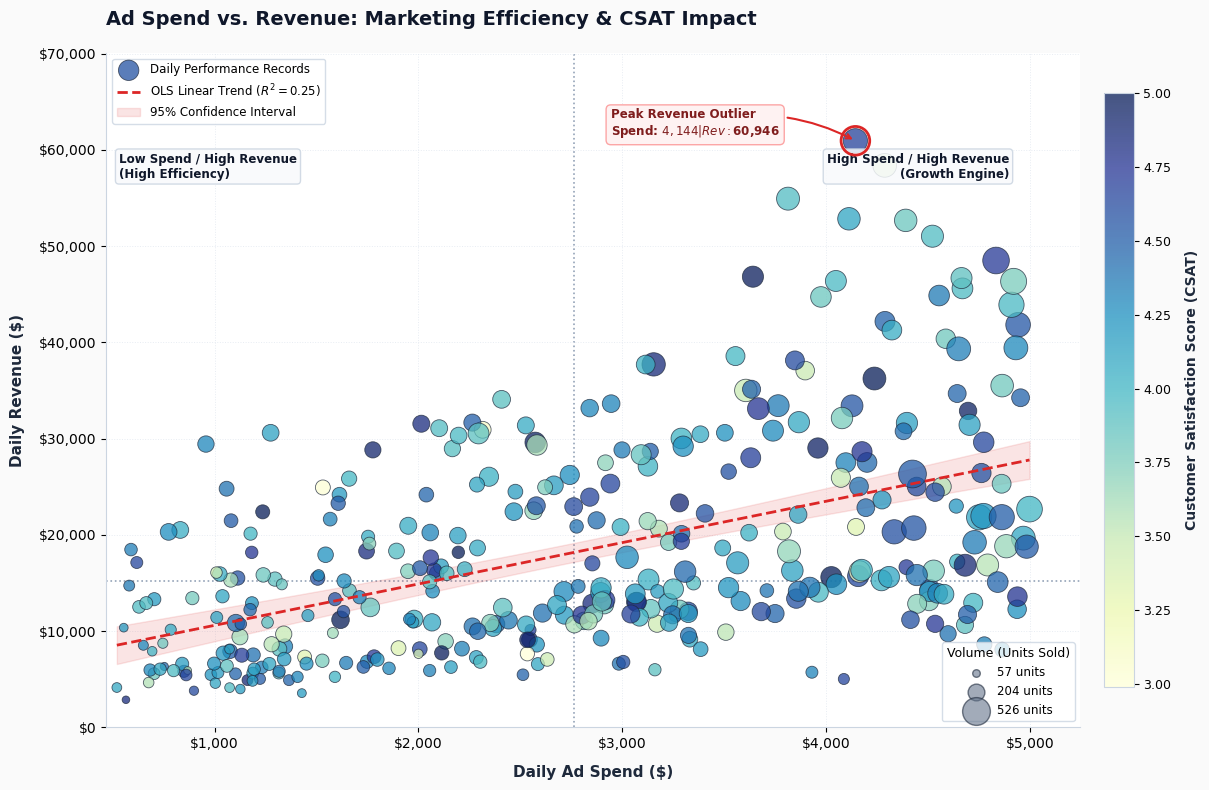

In [11]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
from scipy import stats

# ---------------------------------------------------------
# Data Preparation
# ---------------------------------------------------------
df_scatter = df_main.copy()

x = df_scatter["ad_spend"]
y = df_scatter["revenue"]
sizes = df_scatter["units_sold"]
colors = df_scatter["csat_score"]

# Scale bubble sizes to a visually readable range [30, 400]
sizes_scaled = 30 + (sizes - sizes.min()) / (sizes.max() - sizes.min()) * 370

# ---------------------------------------------------------
# Figure & Axes Setup
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 8), dpi=100)
fig.patch.set_facecolor("#FAFAFA")
ax.set_facecolor("#FFFFFF")

# ---------------------------------------------------------
# 1. Main Scatter Call (4-Dimensional Visual Encoding)
# ---------------------------------------------------------
scatter = ax.scatter(
    x=x,
    y=y,
    s=sizes_scaled,
    c=colors,
    cmap="YlGnBu",
    alpha=0.75,
    edgecolors="#1E293B",
    linewidths=0.6,
    zorder=3,
    label="Daily Performance Records"
)

# ---------------------------------------------------------
# 2. Continuous Colorbar (CSAT Score Encoding)
# ---------------------------------------------------------
cbar = fig.colorbar(scatter, ax=ax, pad=0.02, shrink=0.88)
cbar.set_label("Customer Satisfaction Score (CSAT)", fontsize=10, fontweight="bold", color="#1E293B", labelpad=10)
cbar.ax.tick_params(labelsize=9)
cbar.outline.set_color("#CBD5E1")

# ---------------------------------------------------------
# 3. Statistical Trendline & Confidence Interval Fill
# ---------------------------------------------------------
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
x_seq = np.linspace(x.min(), x.max(), 100)
y_fit = intercept + slope * x_seq

# Linear Regression Line
ax.plot(
    x_seq, y_fit,
    color="#DC2626", linestyle="--", linewidth=2.0,
    label=f"OLS Linear Trend ($R^2 = {r_value**2:.2f}$)", zorder=4
)

# 95% Confidence Interval Band Calculation
n = len(x)
mean_x = np.mean(x)
s_err = np.sqrt(np.sum((y - (intercept + slope * x))**2) / (n - 2))
confs = s_err * np.sqrt(1/n + (x_seq - mean_x)**2 / np.sum((x - mean_x)**2))

ax.fill_between(
    x_seq, y_fit - 1.96 * confs, y_fit + 1.96 * confs,
    color="#DC2626", alpha=0.12, zorder=2, label="95% Confidence Interval"
)

# ---------------------------------------------------------
# 4. Benchmark Reference Lines & Quadrant Matrix
# ---------------------------------------------------------
x_med, y_med = x.median(), y.median()

ax.axvline(x=x_med, color="#94A3B8", linestyle=":", linewidth=1.2, zorder=1)
ax.axhline(y=y_med, color="#94A3B8", linestyle=":", linewidth=1.2, zorder=1)

# Quadrant Strategy Labels
bbox_props = dict(boxstyle="round,pad=0.3", facecolor="#F8FAFC", edgecolor="#CBD5E1", alpha=0.85)
ax.text(x.max() * 0.98, y.max() * 0.98, "High Spend / High Revenue\n(Growth Engine)", ha="right", va="top", fontsize=8.5, fontweight="bold", color="#0F172A", bbox=bbox_props)
ax.text(x.min() * 1.02, y.max() * 0.98, "Low Spend / High Revenue\n(High Efficiency)", ha="left", va="top", fontsize=8.5, fontweight="bold", color="#0F172A", bbox=bbox_props)

# ---------------------------------------------------------
# 5. Peak Data Point Callout & Custom Marker Highlight
# ---------------------------------------------------------
max_idx = y.idxmax()
max_x, max_y = x[max_idx], y[max_idx]

# Outer halo marker on peak point
ax.scatter(max_x, max_y, s=sizes_scaled[max_idx] + 120, facecolors="none", edgecolors="#DC2626", linewidths=2.0, zorder=5)

ax.annotate(
    f"Peak Revenue Outlier\nSpend: ${max_x:,.0f} | Rev: ${max_y:,.0f}",
    xy=(max_x, max_y),
    xytext=(max_x - 1200, max_y + 600),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=-0.2", color="#DC2626", lw=1.5),
    fontsize=8.5, fontweight="bold", color="#7F1D1D",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#FEF2F2", edgecolor="#FCA5A5", lw=1)
)

# ---------------------------------------------------------
# 6. Multi-Legend Configuration (Trend Legend + Size Legend)
# ---------------------------------------------------------
# Primary Trend Legend
leg_main = ax.legend(loc="upper left", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5)
ax.add_artist(leg_main) # Keeps primary legend intact when adding secondary legend

# Secondary Size Legend Construction
size_samples = [sizes.min(), sizes.median(), sizes.max()]
size_handles = []
for val in size_samples:
    s_sc = 30 + (val - sizes.min()) / (sizes.max() - sizes.min()) * 370
    size_handles.append(
        ax.scatter([], [], s=s_sc, c="#64748B", alpha=0.6, edgecolors="#1E293B", label=f"{int(val)} units")
    )

ax.legend(
    handles=size_handles, title="Volume (Units Sold)",
    loc="lower right", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1",
    fontsize=8.5, title_fontsize=9
)

# ---------------------------------------------------------
# 7. Formatting Axes, Spines, Grid & Title
# ---------------------------------------------------------
ax.set_xlabel("Daily Ad Spend ($)", fontsize=11, fontweight="bold", color="#1E293B", labelpad=10)
ax.set_ylabel("Daily Revenue ($)", fontsize=11, fontweight="bold", color="#1E293B", labelpad=10)

ax.xaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))

ax.grid(True, linestyle=":", linewidth=0.7, color="#E2E8F0", alpha=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#CBD5E1")
ax.spines["bottom"].set_color("#CBD5E1")

ax.set_xlim(x.min() * 0.9, x.max() * 1.05)
ax.set_ylim(0, y.max() * 1.15)

plt.title("Ad Spend vs. Revenue: Marketing Efficiency & CSAT Impact", fontsize=14, fontweight="bold", color="#0F172A", pad=20, loc="left")

plt.tight_layout()
plt.show()

## 01.03. **Dumbbell / Connected Scatter Plot** (`ax.scatter` + `ax.hlines`) 
— Variance or point-to-point change comparison between two states.
## 01.04. **Slope Chart** 
— Pre- vs. post-test rate of change comparisons across two discrete categories.

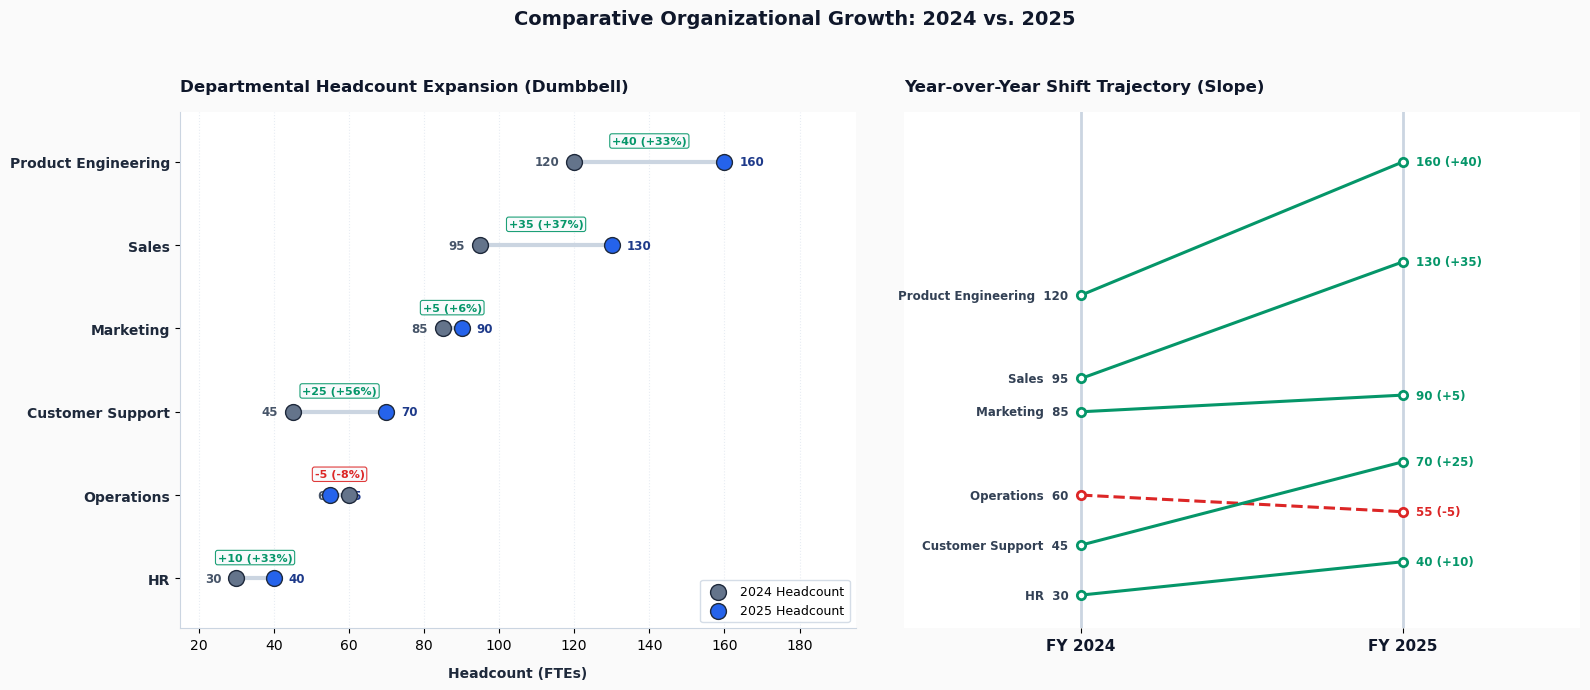

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Data Preparation
# ---------------------------------------------------------
df_comp = df_comparison.copy()
df_comp["delta"] = df_comp["val_2025"] - df_comp["val_2024"]
df_comp["pct_change"] = (df_comp["delta"] / df_comp["val_2024"]) * 100

# Sort by 2025 value for clean hierarchy
df_comp = df_comp.sort_values(by="val_2025", ascending=True).reset_index(drop=True)

# ---------------------------------------------------------
# Figure & Subplots Setup
# ---------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), dpi=100)
fig.patch.set_facecolor("#FAFAFA")

# =========================================================
# SUBPLOT 1: DUMBBELL CHART (Connected Scatter Plot)
# =========================================================
ax1.set_facecolor("#FFFFFF")
y_positions = np.arange(len(df_comp))

# 1. Connecting Range Lines (ax.hlines)
ax1.hlines(
    y=y_positions,
    xmin=df_comp["val_2024"],
    xmax=df_comp["val_2025"],
    color="#CBD5E1", linestyle="-", linewidth=3.0, zorder=2
)

# 2. Year 2024 Data Points (Baseline)
p1 = ax1.scatter(
    df_comp["val_2024"], y_positions,
    color="#64748B", s=130, zorder=4,
    edgecolors="#1E293B", linewidths=1.0, label="2024 Headcount"
)

# 3. Year 2025 Data Points (Current)
p2 = ax1.scatter(
    df_comp["val_2025"], y_positions,
    color="#2563EB", s=130, zorder=4,
    edgecolors="#1E293B", linewidths=1.0, label="2025 Headcount"
)

# 4. Value Callouts & Delta Tags
for i, row in df_comp.iterrows():
    # Value annotations on dots
    ax1.text(row["val_2024"] - 4, i, f"{row['val_2024']}", ha="right", va="center", fontsize=8.5, fontweight="bold", color="#475569")
    ax1.text(row["val_2025"] + 4, i, f"{row['val_2025']}", ha="left", va="center", fontsize=8.5, fontweight="bold", color="#1E3A8A")
    
    # Growth badge (Delta text above dumbbell line)
    color_badge = "#059669" if row["delta"] >= 0 else "#DC2626"
    mid_point = (row["val_2024"] + row["val_2025"]) / 2
    ax1.text(
        mid_point, i + 0.25, f"{row['delta']:+d} ({row['pct_change']:+.0f}%)",
        ha="center", va="center", fontsize=8.0, fontweight="bold", color=color_badge,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="#F8FAFC", edgecolor=color_badge, lw=0.8, alpha=0.9)
    )

# Formatting Subplot 1
ax1.set_yticks(y_positions)
ax1.set_yticklabels(df_comp["category"], fontsize=10, fontweight="bold", color="#1E293B")
ax1.set_xlabel("Headcount (FTEs)", fontsize=10, fontweight="bold", color="#1E293B", labelpad=10)
ax1.set_title("Departmental Headcount Expansion (Dumbbell)", fontsize=12, fontweight="bold", color="#0F172A", loc="left", pad=15)

ax1.set_xlim(15, df_comp["val_2025"].max() + 35)
ax1.set_ylim(-0.6, len(df_comp) - 0.4)
ax1.grid(True, axis="x", linestyle=":", color="#E2E8F0", alpha=0.8)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.spines["left"].set_color("#CBD5E1")
ax1.spines["bottom"].set_color("#CBD5E1")

ax1.legend(loc="lower right", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=9)


# =========================================================
# SUBPLOT 2: SLOPE CHART (Rate of Change Trajectories)
# =========================================================
ax2.set_facecolor("#FFFFFF")

# X-coordinates for 2-point slope lines
x_start, x_end = 0, 1

# Vertical Pillar Lines
ax2.axvline(x=x_start, color="#CBD5E1", linestyle="-", linewidth=2.0, zorder=1)
ax2.axvline(x=x_end, color="#CBD5E1", linestyle="-", linewidth=2.0, zorder=1)

# Plot Slope Trajectories per Department
for i, row in df_comp.iterrows():
    val24, val25 = row["val_2024"], row["val_2025"]
    is_positive = val25 >= val24
    
    line_color = "#059669" if is_positive else "#DC2626"
    line_style = "-" if is_positive else "--"
    
    # 1. Slope Line
    ax2.plot(
        [x_start, x_end], [val24, val25],
        color=line_color, linestyle=line_style, linewidth=2.2,
        marker="o", markersize=6, markerfacecolor="#FFFFFF", markeredgewidth=2.0, zorder=3
    )
    
    # 2. Left Label (Category + 2024 Value)
    ax2.text(
        x_start - 0.04, val24, f"{row['category']}  {val24}",
        ha="right", va="center", fontsize=8.5, fontweight="bold", color="#334155"
    )
    
    # 3. Right Label (2025 Value + Change Tag)
    ax2.text(
        x_end + 0.04, val25, f"{val25} ({row['delta']:+d})",
        ha="left", va="center", fontsize=8.5, fontweight="bold", color=line_color
    )

# Formatting Subplot 2
ax2.set_xticks([x_start, x_end])
ax2.set_xticklabels(["FY 2024", "FY 2025"], fontsize=11, fontweight="bold", color="#0F172A")
ax2.set_title("Year-over-Year Shift Trajectory (Slope)", fontsize=12, fontweight="bold", color="#0F172A", loc="left", pad=15)

# Hide unnecessary axes elements for clean slope visualization
ax2.set_xlim(-0.55, 1.55)
ax2.set_ylim(20, df_comp["val_2025"].max() + 15)
ax2.get_yaxis().set_visible(False)

for spine in ax2.spines.values():
    spine.set_visible(False)

# ---------------------------------------------------------
# Global Layout Title Adjustments
# ---------------------------------------------------------
plt.suptitle("Comparative Organizational Growth: 2024 vs. 2025", fontsize=14, fontweight="bold", color="#0F172A", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 01.05. **Step / Stairs Plot** (`ax.step`, `ax.stairs`)
— Discrete inventory tracking, price-tier step changes, and threshold changes.
## 01.06. **Stacked Area Chart** (`ax.stackplot`)
— Cumulative composition trends and total volume changes over time.

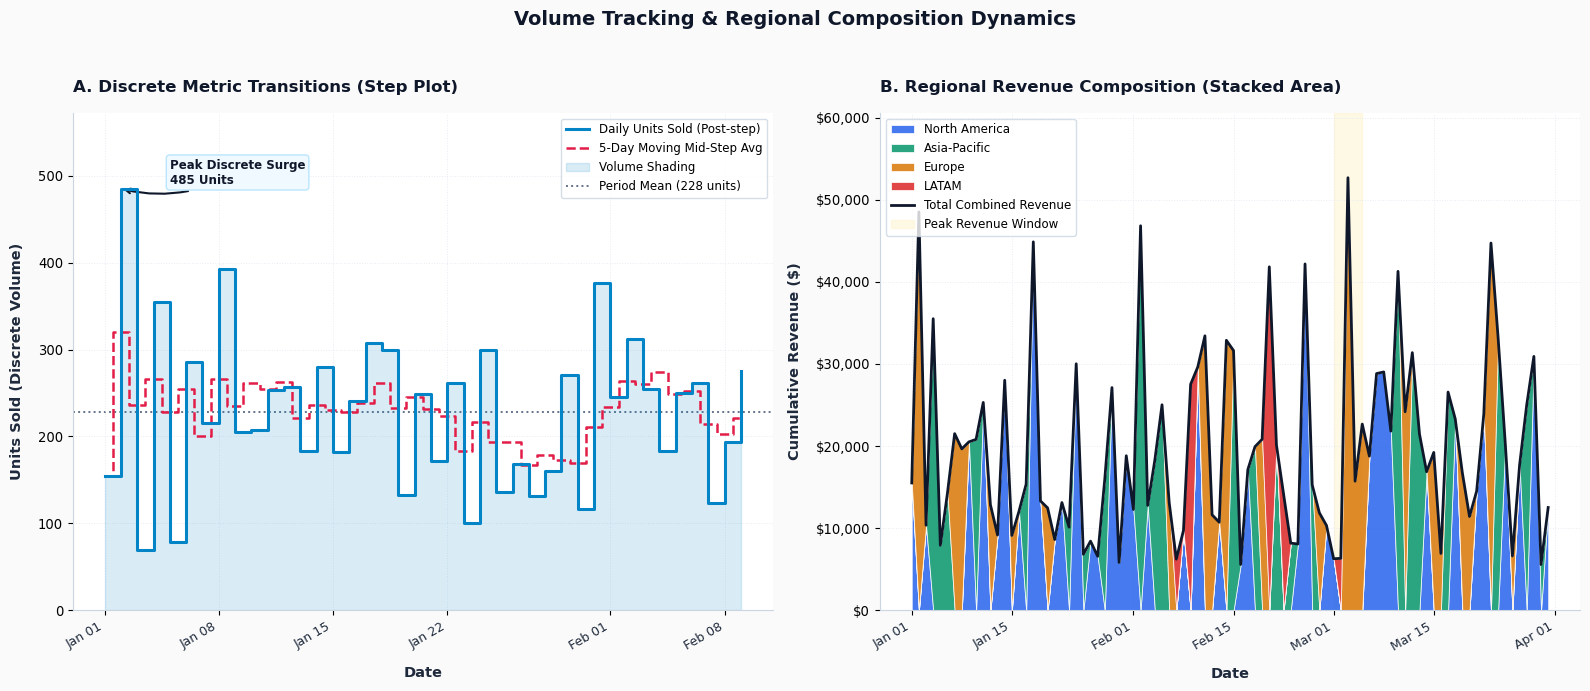

In [13]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# Data Preparation
# ---------------------------------------------------------
# Subsets for crisp step visualization and clean stacked composition
df_step = df_main.iloc[:40].copy()
df_area = df_main.iloc[:90].copy()

# Pivot regional revenue for the Stacked Area chart
area_pivot = df_area.pivot_table(
    index="date", columns="region", values="revenue", aggfunc="sum"
).fillna(0)

# Sort columns by total revenue volume for optimal visual stacking order
region_totals = area_pivot.sum().sort_values(ascending=False)
area_pivot = area_pivot[region_totals.index]

# ---------------------------------------------------------
# Figure & Subplot Canvas Setup
# ---------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), dpi=100)
fig.patch.set_facecolor("#FAFAFA")
ax1.set_facecolor("#FFFFFF")
ax2.set_facecolor("#FFFFFF")

# =========================================================
# SUBPLOT 1: Step Plot (Discrete Inventory Transitions)
# =========================================================
# 1. Primary Step Series (Post-step transition rule)
ax1.step(
    df_step["date"], df_step["units_sold"],
    where="post", color="#0284C7", linewidth=2.2,
    label="Daily Units Sold (Post-step)", zorder=4
)

# 2. Secondary Benchmark Step Series (Mid-step transition rule)
rolling_mid = df_step["units_sold"].rolling(5, min_periods=1).mean()
ax1.step(
    df_step["date"], rolling_mid,
    where="mid", color="#E11D48", linestyle="--", linewidth=1.8,
    label="5-Day Moving Mid-Step Avg", zorder=3
)

# 3. Shaded Region Under Step Line
ax1.fill_between(
    df_step["date"], df_step["units_sold"],
    step="post", alpha=0.15, color="#0284C7", zorder=2,
    label="Volume Shading"
)

# 4. Horizontal Benchmark Line
mean_units = df_step["units_sold"].mean()
ax1.axhline(
    y=mean_units, color="#64748B", linestyle=":", linewidth=1.4,
    label=f"Period Mean ({mean_units:.0f} units)", zorder=1
)

# 5. Peak Annotation Callout
max_idx = df_step["units_sold"].idxmax()
max_date = df_step.loc[max_idx, "date"]
max_val = df_step.loc[max_idx, "units_sold"]

ax1.annotate(
    f"Peak Discrete Surge\n{max_val} Units",
    xy=(max_date, max_val),
    xytext=(max_date + pd.Timedelta(days=3), max_val + 6),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=-0.2", color="#0F172A", lw=1.5),
    fontsize=8.5, fontweight="bold", color="#0F172A",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="#F0F9FF", edgecolor="#BAE6FD", lw=1)
)

# Formatting Subplot 1
ax1.set_title("A. Discrete Metric Transitions (Step Plot)", fontsize=12, fontweight="bold", color="#0F172A", loc="left", pad=15)
ax1.set_ylabel("Units Sold (Discrete Volume)", fontsize=10.5, fontweight="bold", color="#1E293B", labelpad=10)
ax1.set_xlabel("Date", fontsize=10.5, fontweight="bold", color="#1E293B", labelpad=10)

ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.setp(ax1.get_xticklabels(), rotation=30, ha="right", fontsize=9, color="#1E293B")
ax1.tick_params(axis="y", labelsize=9.5)

ax1.grid(True, linestyle=":", linewidth=0.7, color="#E2E8F0", alpha=0.8)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.spines["left"].set_color("#CBD5E1")
ax1.spines["bottom"].set_color("#CBD5E1")

ax1.set_ylim(0, df_step["units_sold"].max() * 1.18)
ax1.legend(loc="upper right", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5)

# =========================================================
# SUBPLOT 2: Stacked Area Chart (Cumulative Composition)
# =========================================================
regions = area_pivot.columns.tolist()
palette = ["#2563EB", "#059669", "#D97706", "#DC2626"]

# 1. Stacked Area Fill
stacks = ax2.stackplot(
    area_pivot.index,
    [area_pivot[col] for col in regions],
    labels=regions,
    colors=palette,
    alpha=0.85,
    edgecolor="#FFFFFF",
    linewidth=0.6,
    zorder=2
)

# 2. Total Overlay Trend Line
total_revenue = area_pivot.sum(axis=1)
ax2.plot(
    area_pivot.index, total_revenue,
    color="#0F172A", linewidth=2.0, linestyle="-",
    label="Total Combined Revenue", zorder=4
)

# 3. Highlight Span for Highest Volume Week
max_total_date = total_revenue.idxmax()
ax2.axvspan(
    max_total_date - pd.Timedelta(days=2), max_total_date + pd.Timedelta(days=2),
    color="#FEF3C7", alpha=0.45, label="Peak Revenue Window", zorder=1
)

# Formatting Subplot 2
ax2.set_title("B. Regional Revenue Composition (Stacked Area)", fontsize=12, fontweight="bold", color="#0F172A", loc="left", pad=15)
ax2.set_ylabel("Cumulative Revenue ($)", fontsize=10.5, fontweight="bold", color="#1E293B", labelpad=10)
ax2.set_xlabel("Date", fontsize=10.5, fontweight="bold", color="#1E293B", labelpad=10)

ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.setp(ax2.get_xticklabels(), rotation=30, ha="right", fontsize=9, color="#1E293B")
ax2.tick_params(axis="y", labelsize=9.5)

ax2.grid(True, linestyle=":", linewidth=0.7, color="#E2E8F0", alpha=0.8)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_color("#CBD5E1")
ax2.spines["bottom"].set_color("#CBD5E1")

ax2.set_ylim(0, total_revenue.max() * 1.15)
ax2.legend(loc="upper left", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5)

# Overall Super Title
plt.suptitle("Volume Tracking & Regional Composition Dynamics", fontsize=14, fontweight="bold", color="#0F172A", y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 01.07. **Streamgraph** (`ax.stackplot` with `baseline='wiggle'`)
— Centered, organic volume flow trends across continuous categories.

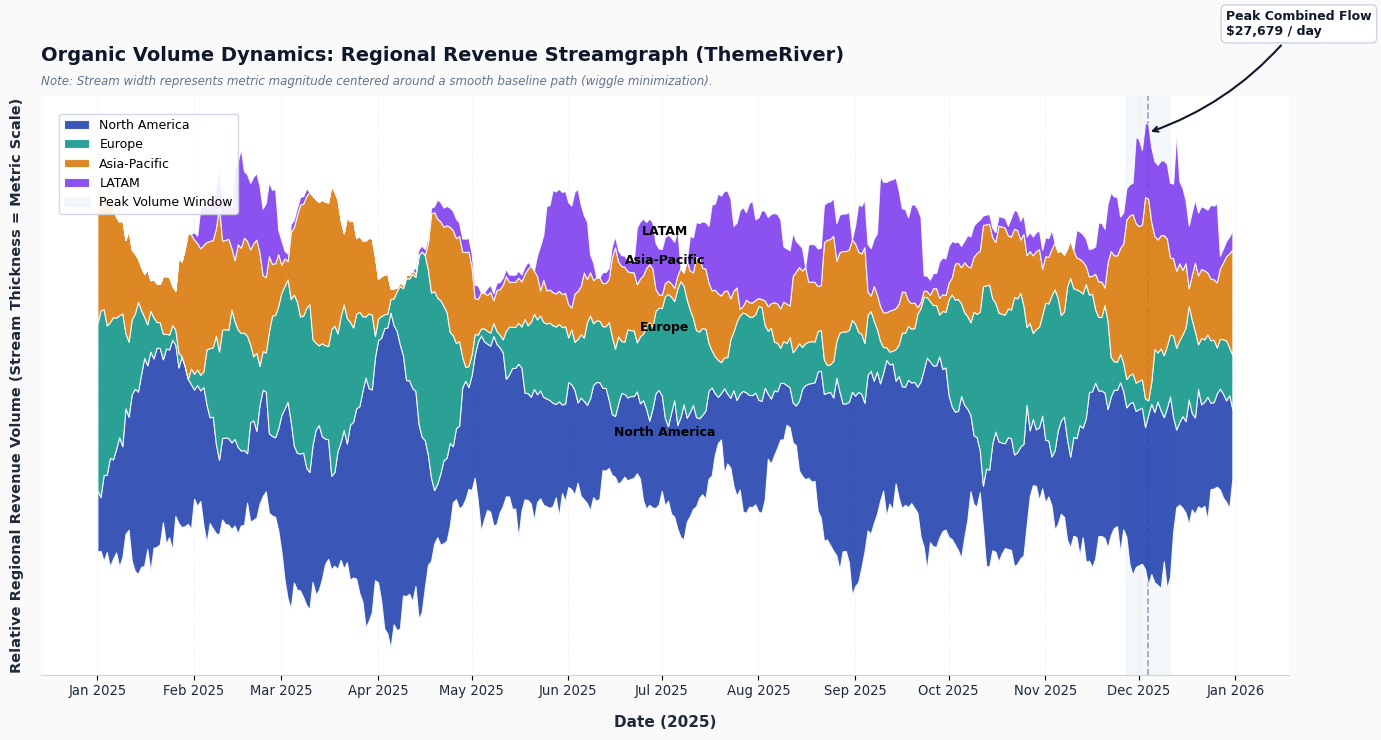

In [14]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# Data Preparation for Streamgraph
# ---------------------------------------------------------
# Pivot regional revenue over the full 365-day dataset
df_stream = df_main.pivot_table(
    index="date", columns="region", values="revenue", aggfunc="sum"
).fillna(0)

# Apply a 14-day centered rolling mean to smooth daily noise into fluid stream curves
df_stream_smooth = df_stream.rolling(window=14, min_periods=1, center=True).mean()

# Order regions by overall volume contribution
regions = df_stream_smooth.sum().sort_values(ascending=False).index.tolist()
df_stream_smooth = df_stream_smooth[regions]

# Prepare matrix array for stackplot (transposed so rows correspond to series)
y_data = [df_stream_smooth[col].values for col in regions]
x_data = df_stream_smooth.index

# ---------------------------------------------------------
# Figure & Canvas Setup
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 7.5), dpi=100)
fig.patch.set_facecolor("#FAFAFA")
ax.set_facecolor("#FFFFFF")

# ---------------------------------------------------------
# 1. Main Streamgraph Call (baseline='wiggle')
# ---------------------------------------------------------
# Palette chosen for high visual distinction and organic flow
palette = ["#1E40AF", "#0D9488", "#D97706", "#7C3AED"]

streams = ax.stackplot(
    x_data,
    *y_data,
    baseline="wiggle",  # Centers data around a smooth baseline by minimizing squared slopes
    labels=regions,
    colors=palette,
    alpha=0.88,
    edgecolor="#FFFFFF",
    linewidth=0.8,
    zorder=3
)

# ---------------------------------------------------------
# 2. Peak Flow Span & Direct Stream Annotations
# ---------------------------------------------------------
# Highlight the max total revenue period (Surge Window)
total_smooth = df_stream_smooth.sum(axis=1)
peak_date = total_smooth.idxmax()

ax.axvspan(
    peak_date - pd.Timedelta(days=7), peak_date + pd.Timedelta(days=7),
    color="#F1F5F9", alpha=0.75, zorder=1, label="Peak Volume Window"
)
ax.axvline(
    x=peak_date, color="#94A3B8", linestyle="--", linewidth=1.2, zorder=2
)

# Annotation for total peak flow rate
max_vol = total_smooth.max()
ax.annotate(
    f"Peak Combined Flow\n${max_vol:,.0f} / day",
    xy=(peak_date, total_smooth.loc[peak_date] / 2.2),
    xytext=(peak_date + pd.Timedelta(days=25), total_smooth.loc[peak_date] / 1.5),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=-0.15", color="#0F172A", lw=1.5),
    fontsize=9, fontweight="bold", color="#0F172A",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#FFFFFF", edgecolor="#CBD5E1", lw=1)
)

# Direct Labeling inside larger streams at midpoint for quick scanning
mid_idx = len(df_stream_smooth) // 2
mid_date = df_stream_smooth.index[mid_idx]

# Calculate approximate Y-offsets for labels on the stream at mid_date
# Note: Streamgraph y-coordinates are centered around zero
cum_y = -total_smooth.iloc[mid_idx] / 2.0  # approximate starting baseline offset
for col, color in zip(regions, palette):
    val = df_stream_smooth.loc[mid_date, col]
    y_pos = cum_y + (val / 2.0)
    ax.text(
        mid_date, y_pos, col,
        ha="center", va="center", fontsize=9, fontweight="bold", color="#000000",
        bbox=dict(boxstyle="square,pad=0.15", facecolor="none", edgecolor="none")
    )
    cum_y += val

# ---------------------------------------------------------
# 3. Formatting Axes, Spines & Grid
# ---------------------------------------------------------
ax.set_xlabel("Date (2025)", fontsize=11, fontweight="bold", color="#1E293B", labelpad=12)

# Streamgraphs shift baseline coordinates, making absolute Y-ticks meaningless.
# Standard practice is to remove Y-ticks and add a descriptive label/scale indicator.
ax.set_ylabel("Relative Regional Revenue Volume (Stream Thickness = Metric Scale)", 
             fontsize=10.5, fontweight="bold", color="#1E293B", labelpad=12)
ax.set_yticks([])

# X-Axis Date Formatting
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax.get_xticklabels(), rotation=0, ha="center", fontsize=9.5, color="#1E293B")

# Gridlines & Spines
ax.grid(True, axis="x", linestyle=":", linewidth=0.8, color="#E2E8F0", alpha=0.8, zorder=1)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#CBD5E1")

# ---------------------------------------------------------
# 4. Title, Subtitle & Legend
# ---------------------------------------------------------
plt.title("Organic Volume Dynamics: Regional Revenue Streamgraph (ThemeRiver)", 
          fontsize=14, fontweight="bold", color="#0F172A", pad=25, loc="left")

# Explanation note for reading streamgraphs
ax.text(
    0.0, 1.02, "Note: Stream width represents metric magnitude centered around a smooth baseline path (wiggle minimization).",
    transform=ax.transAxes, fontsize=8.5, fontstyle="italic", color="#64748B"
)

# Unified Legend Box
ax.legend(
    loc="upper left", bbox_to_anchor=(0.01, 0.98),
    frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", framealpha=0.9, fontsize=9
)

plt.tight_layout()
plt.show()

# 02. **Categorical, Business & Compositional**
## 02.01. **Vertical & Horizontal Bar Charts** (`ax.bar`, `ax.barh`)
— Core categorical metric comparisons (horizontal for long labels).
## 02.02. **Grouped & Stacked Bar Charts**
— Multi-variable categorical breakdowns and part-to-whole segmentations.

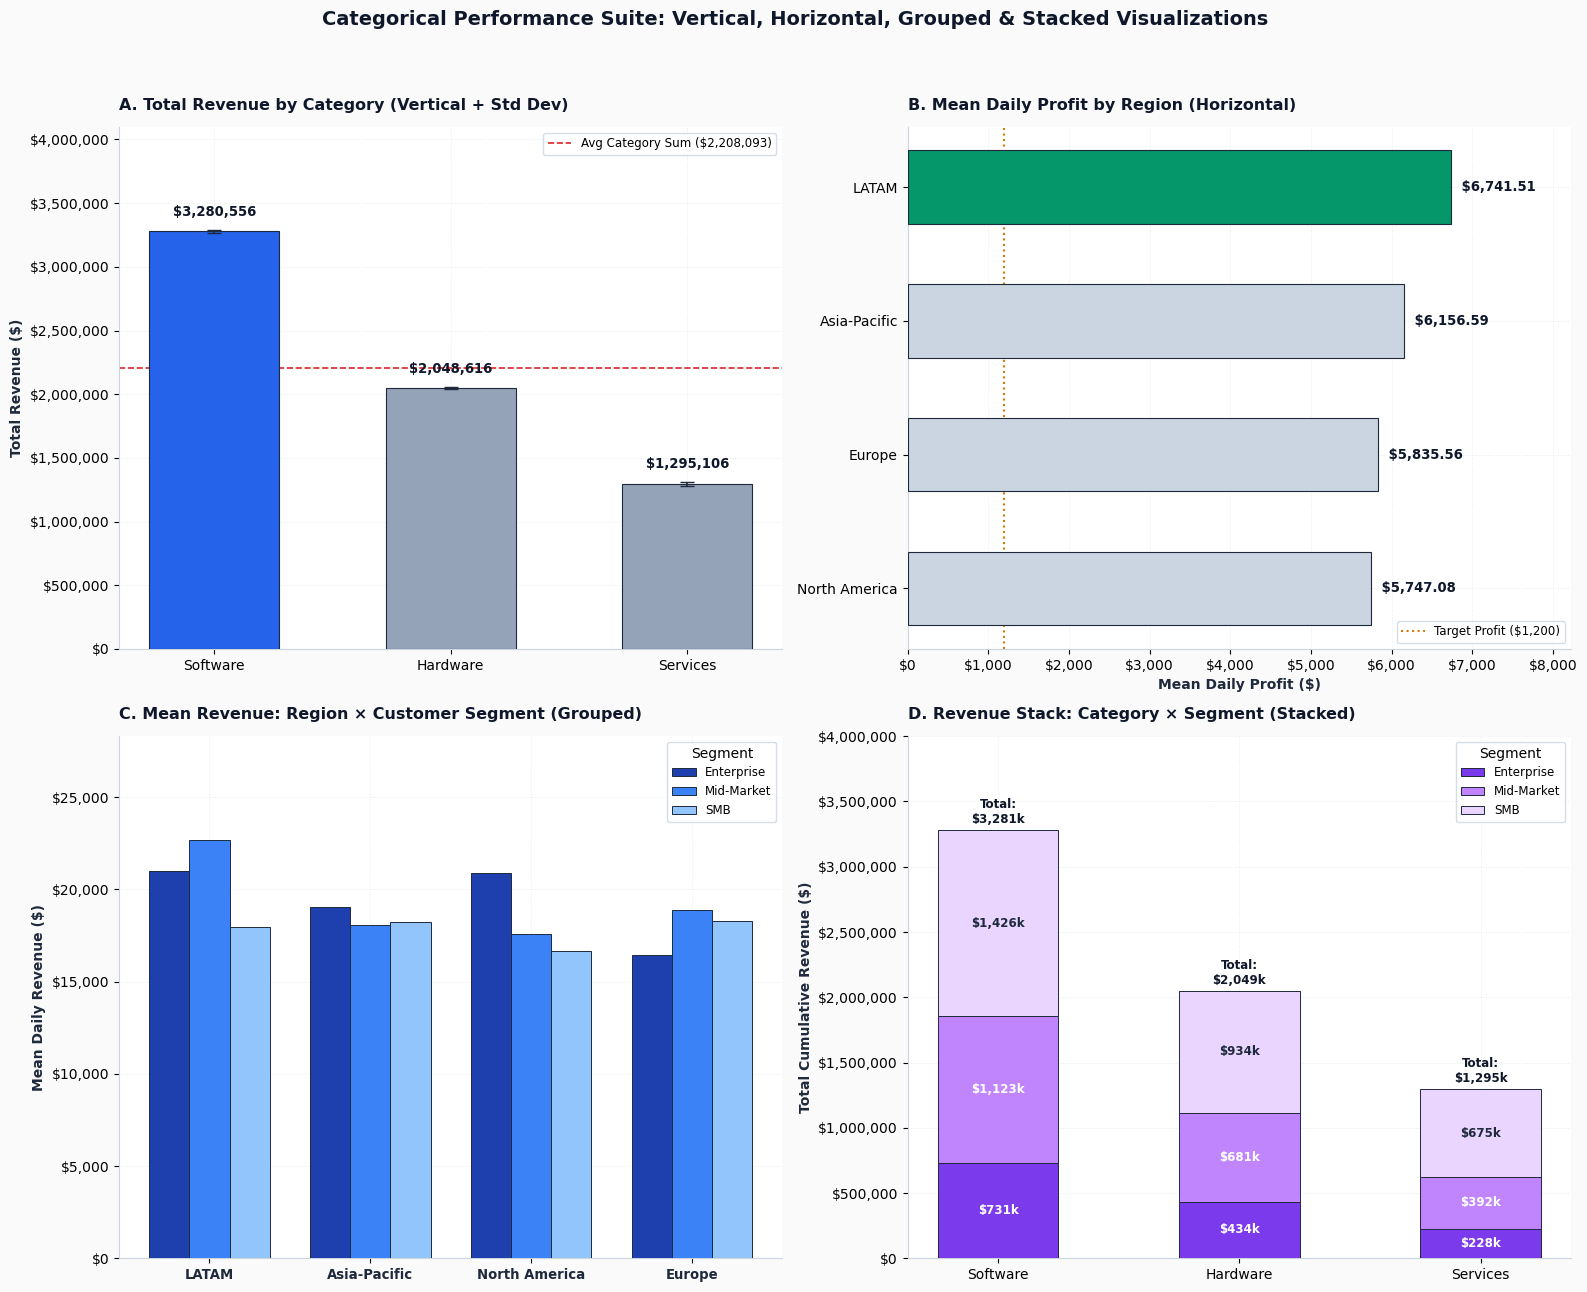

In [15]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Data Preparation & Aggregations from df_main
# ---------------------------------------------------------
# 1. Vertical Bar: Total Revenue & Volatility by Category
cat_summary = df_main.groupby("category")["revenue"].agg(["sum", "std"]).reset_index()
cat_summary = cat_summary.sort_values("sum", ascending=False).reset_index(drop=True)

# 2. Horizontal Bar: Mean Profit by Region
reg_summary = df_main.groupby("region")["profit"].mean().reset_index()
reg_summary = reg_summary.sort_values("profit", ascending=True).reset_index(drop=True)

# 3. Grouped Bar: Mean Revenue by Region & Customer Segment
grouped_df = df_main.groupby(["region", "customer_segment"])["revenue"].mean().unstack()
# Reorder regions by total mean revenue
region_order = grouped_df.sum(axis=1).sort_values(ascending=False).index
grouped_df = grouped_df.loc[region_order]

# 4. Stacked Bar: Total Revenue by Category & Customer Segment
stacked_df = df_main.groupby(["category", "customer_segment"])["revenue"].sum().unstack()
stacked_df = stacked_df.loc[cat_summary["category"]] # Match vertical bar sorting

# ---------------------------------------------------------
# Figure & 2x2 Subplot Grid Setup
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 13), dpi=100)
fig.patch.set_facecolor("#FAFAFA")
(ax1, ax2), (ax3, ax4) = axes

for ax in [ax1, ax2, ax3, ax4]:
    ax.set_facecolor("#FFFFFF")

# =========================================================
# SUBPLOT 1: Vertical Bar Chart with Error Bars & Highlights
# =========================================================
colors_v = ["#2563EB" if i == 0 else "#94A3B8" for i in range(len(cat_summary))]

bars1 = ax1.bar(
    cat_summary["category"], cat_summary["sum"],
    yerr=cat_summary["std"], capsize=5, ecolor="#1E293B", error_kw={"elinewidth": 1.2},
    color=colors_v, edgecolor="#1E293B", linewidth=0.8, width=0.55, zorder=3
)

# Value Labels on Top of Bars
ax1.bar_label(
    bars1, labels=[f"${val:,.0f}" for val in cat_summary["sum"]],
    padding=8, fontsize=9.5, fontweight="bold", color="#0F172A"
)

# Reference Line for Category Average
mean_cat_sum = cat_summary["sum"].mean()
ax1.axhline(mean_cat_sum, color="#DC2626", linestyle="--", linewidth=1.2, zorder=2, label=f"Avg Category Sum (${mean_cat_sum:,.0f})")

ax1.set_title("A. Total Revenue by Category (Vertical + Std Dev)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax1.set_ylabel("Total Revenue ($)", fontsize=10, fontweight="bold", color="#1E293B")
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
ax1.set_ylim(0, cat_summary["sum"].max() * 1.25)
ax1.legend(loc="upper right", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5)

# =========================================================
# SUBPLOT 2: Horizontal Bar Chart (Best for Long Labels)
# =========================================================
colors_h = ["#059669" if i == len(reg_summary) - 1 else "#CBD5E1" for i in range(len(reg_summary))]

bars2 = ax2.barh(
    reg_summary["region"], reg_summary["profit"],
    color=colors_h, edgecolor="#1E293B", linewidth=0.8, height=0.55, zorder=3
)

# Value Labels at End of Horizontal Bars
ax2.bar_label(
    bars2, labels=[f" ${val:,.2f}" for val in reg_summary["profit"]],
    padding=4, fontsize=9.5, fontweight="bold", color="#0F172A"
)

# Vertical Target Line
target_profit = 1200
ax2.axvline(target_profit, color="#D97706", linestyle=":", linewidth=1.5, zorder=2, label=f"Target Profit (${target_profit:,.0f})")

ax2.set_title("B. Mean Daily Profit by Region (Horizontal)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax2.set_xlabel("Mean Daily Profit ($)", fontsize=10, fontweight="bold", color="#1E293B")
ax2.xaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
ax2.set_xlim(0, reg_summary["profit"].max() * 1.22)
ax2.legend(loc="lower right", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5)

# =========================================================
# SUBPLOT 3: Grouped Bar Chart (Multi-Series Side-by-Side)
# =========================================================
x_indices = np.arange(len(grouped_df))
bar_width = 0.25
segments = ["Enterprise", "Mid-Market", "SMB"]
seg_colors = ["#1E40AF", "#3B82F6", "#93C5FD"]

for i, seg in enumerate(segments):
    offset = (i - 1) * bar_width
    bars3 = ax3.bar(
        x_indices + offset, grouped_df[seg],
        width=bar_width, label=seg, color=seg_colors[i],
        edgecolor="#1E293B", linewidth=0.7, zorder=3
    )

ax3.set_xticks(x_indices)
ax3.set_xticklabels(grouped_df.index, fontsize=9.5, fontweight="bold", color="#1E293B")
ax3.set_title("C. Mean Revenue: Region × Customer Segment (Grouped)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax3.set_ylabel("Mean Daily Revenue ($)", fontsize=10, fontweight="bold", color="#1E293B")
ax3.yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
ax3.set_ylim(0, grouped_df.values.max() * 1.25)
ax3.legend(title="Segment", loc="upper right", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5)

# =========================================================
# SUBPLOT 4: Stacked Bar Chart (Part-to-Whole Composition)
# =========================================================
bottom_values = np.zeros(len(stacked_df))
stack_colors = ["#7C3AED", "#C084FC", "#E9D5FF"]

for i, seg in enumerate(segments):
    values = stacked_df[seg].values
    bars4 = ax4.bar(
        stacked_df.index, values, bottom=bottom_values,
        label=seg, color=stack_colors[i], edgecolor="#1E293B", linewidth=0.7, width=0.5, zorder=3
    )
    
    # Segment Value Text Labels inside stacks
    for idx, (val, b_val) in enumerate(zip(values, bottom_values)):
        if val > 150000: # Label only significant segments for visual cleanliness
            ax4.text(
                idx, b_val + val / 2, f"${val/1e3:,.0f}k",
                ha="center", va="center", fontsize=8.5, fontweight="bold", color="#FFFFFF" if i < 2 else "#1E293B"
            )
            
    bottom_values += values

# Total Stack Value Labels on Top
for idx, total in enumerate(bottom_values):
    ax4.text(idx, total + 30000, f"Total:\n${total/1e3:,.0f}k", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#0F172A")

ax4.set_title("D. Revenue Stack: Category × Segment (Stacked)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax4.set_ylabel("Total Cumulative Revenue ($)", fontsize=10, fontweight="bold", color="#1E293B")
ax4.yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
ax4.set_ylim(0, bottom_values.max() * 1.22)
ax4.legend(title="Segment", loc="upper right", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5)

# ---------------------------------------------------------
# Grid & Spine Styling across all Subplots
# ---------------------------------------------------------
for ax in [ax1, ax2, ax3, ax4]:
    ax.grid(True, linestyle=":", linewidth=0.7, color="#E2E8F0", alpha=0.8, zorder=1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#CBD5E1")
    ax.spines["bottom"].set_color("#CBD5E1")

plt.suptitle("Categorical Performance Suite: Vertical, Horizontal, Grouped & Stacked Visualizations", 
             fontsize=14, fontweight="bold", color="#0F172A", y=0.99)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 02.03. **Waterfall Chart**
— Sequential net financial, inventory, or user gains and losses.
## 02.04. **Conversion Funnel Chart**
— Step-by-step customer drop-offs across sales pipelines or product onboarding.
## 02.05. **Bullet Chart**
— KPI performance metrics evaluated against target benchmarks and qualitative bands.
## 02.06. **Gantt / Timeline Chart** (`ax.broken_barh`)
— Project milestone schedules and operational resource allocations.

NameError: name 'Patch' is not defined

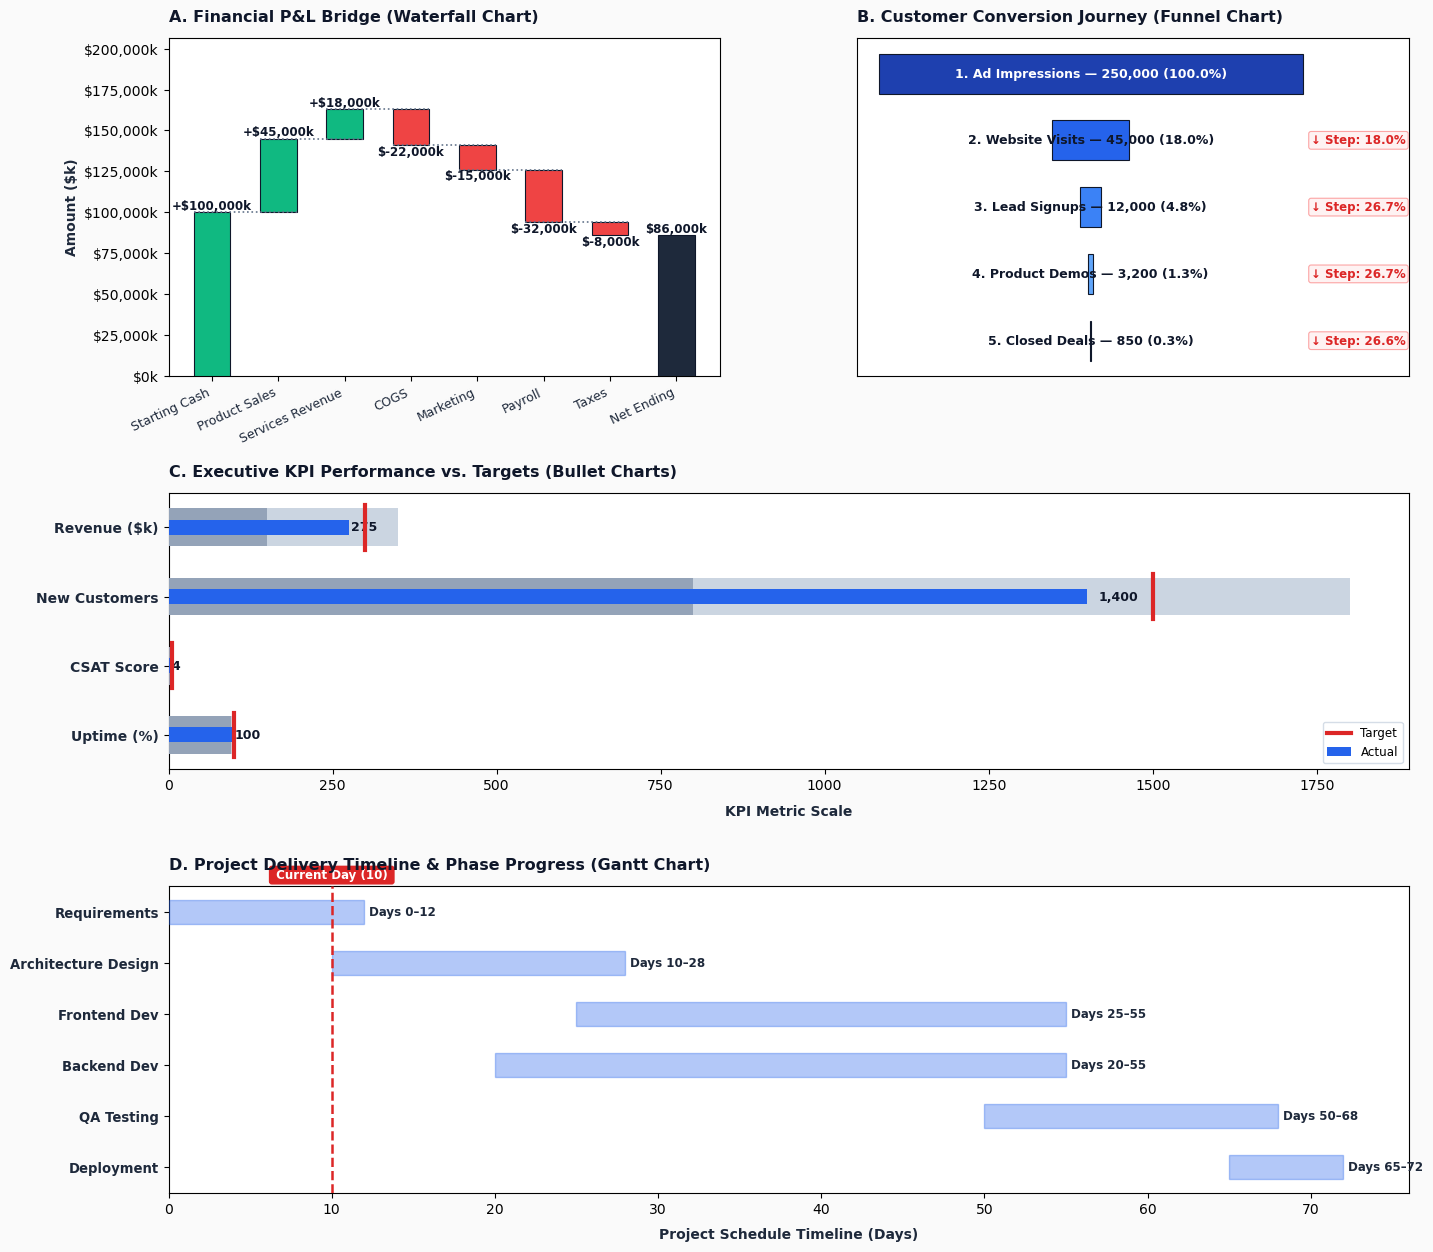

In [16]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Figure & Canvas Setup (4 Custom Subplots Grid across 3 Rows)
# ---------------------------------------------------------
fig = plt.figure(figsize=(16, 15), dpi=100)
fig.patch.set_facecolor("#FAFAFA")

# Create grid: Top 2 subplots for Waterfall & Funnel, Row 2 for Bullet, Row 3 for Gantt Timeline
gs = fig.add_gridspec(3, 2, height_ratios=[1.1, 0.9, 1.0], hspace=0.38, wspace=0.25)

ax_waterfall = fig.add_subplot(gs[0, 0])
ax_funnel = fig.add_subplot(gs[0, 1])
ax_bullet = fig.add_subplot(gs[1, :])
ax_gantt = fig.add_subplot(gs[2, :])

for ax in [ax_waterfall, ax_funnel, ax_bullet, ax_gantt]:
    ax.set_facecolor("#FFFFFF")

# =========================================================
# 1. WATERFALL CHART (Financial Income/P&L Bridge)
# =========================================================
df_wf = df_waterfall.copy()

wf_label_col = "stage" if "stage" in df_wf.columns else df_wf.columns[0]
wf_val_col = "amount" if "amount" in df_wf.columns else ([c for c in df_wf.columns if c != wf_label_col][0] if len(df_wf.columns) > 1 else df_wf.columns[0])

cum_sum = df_wf[wf_val_col].cumsum()
bottoms = cum_sum.shift(1).fillna(0)

if "type" in df_wf.columns:
    is_total = df_wf["type"] == "total"
    bottoms[is_total] = 0
    types = df_wf["type"]
else:
    is_total = pd.Series([False] * len(df_wf))
    types = ["item"] * len(df_wf)

colors_wf = []
for t, val in zip(types, df_wf[wf_val_col]):
    if t == "total":
        colors_wf.append("#1E293B")
    elif val >= 0:
        colors_wf.append("#10B981")
    else:
        colors_wf.append("#EF4444")

bars_wf = ax_waterfall.bar(
    df_wf[wf_label_col], df_wf[wf_val_col], bottom=bottoms,
    color=colors_wf, edgecolor="#0F172A", linewidth=0.8, width=0.55, zorder=3
)

for i in range(len(df_wf) - 1):
    if not is_total.iloc[i + 1]:
        y_conn = cum_sum.iloc[i]
        ax_waterfall.plot([i - 0.275, i + 1 + 0.275], [y_conn, y_conn], color="#64748B", linestyle=":", linewidth=1.2, zorder=4)

for i, (val, bottom, t) in enumerate(zip(df_wf[wf_val_col], bottoms, types)):
    sign = "+" if val > 0 and t != "total" else ""
    y_pos = (bottom + val + 15) if val >= 0 else (bottom + val - 25)
    ax_waterfall.text(
        i, y_pos, f"{sign}${val:,.0f}k",
        ha="center", va="bottom" if val >= 0 else "top",
        fontsize=8.5, fontweight="bold", color="#0F172A"
    )

ax_waterfall.set_title("A. Financial P&L Bridge (Waterfall Chart)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_waterfall.set_ylabel("Amount ($k)", fontsize=10, fontweight="bold", color="#1E293B")
ax_waterfall.yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}k"))
plt.setp(ax_waterfall.get_xticklabels(), rotation=25, ha="right", fontsize=9, color="#1E293B")
ax_waterfall.set_ylim(0, max(cum_sum.max(), 10) * 1.2)

# =========================================================
# 2. CONVERSION FUNNEL (Sales & User Journey)
# =========================================================
df_fn = df_funnel.copy()

fn_label_col = "stage" if "stage" in df_fn.columns else df_fn.columns[0]
fn_val_col = "users" if "users" in df_fn.columns else ([c for c in df_fn.columns if c != fn_label_col][0] if len(df_fn.columns) > 1 else df_fn.columns[0])

max_users = df_fn[fn_val_col].iloc[0]

df_fn["conv_rate"] = (df_fn[fn_val_col] / max_users) * 100
df_fn["drop_off"] = (df_fn[fn_val_col] / df_fn[fn_val_col].shift(1)).fillna(1.0) * 100

y_positions = np.arange(len(df_fn))[::-1]
funnel_colors = ["#1E40AF", "#2563EB", "#3B82F6", "#60A5FA", "#93C5FD"]

for i, (y, row) in enumerate(zip(y_positions, df_fn.iterrows())):
    users = row[1][fn_val_col]
    width = users
    left_offset = (max_users - width) / 2
    
    ax_funnel.barh(y, width, left=left_offset, color=funnel_colors[i % len(funnel_colors)], 
                   edgecolor="#0F172A", linewidth=0.8, height=0.6, zorder=3)
    
    ax_funnel.text(
        max_users / 2, y, 
        f"{row[1][fn_label_col]} — {users:,.0f} ({row[1]['conv_rate']:.1f}%)",
        ha="center", va="center", fontsize=9, fontweight="bold", color="#FFFFFF" if i < 1 else "#0F172A", zorder=4
    )
    
    if i > 0:
        step_conv = row[1]["drop_off"]
        ax_funnel.text(
            max_users * 1.02, y, f"↓ Step: {step_conv:.1f}%",
            ha="left", va="center", fontsize=8.5, fontweight="bold", color="#DC2626",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="#FEF2F2", edgecolor="#FCA5A5", lw=0.8)
        )

ax_funnel.set_title("B. Customer Conversion Journey (Funnel Chart)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_funnel.set_yticks([])
ax_funnel.set_xticks([])
ax_funnel.set_xlim(-max_users * 0.05, max_users * 1.25)

# =========================================================
# 3. BULLET CHART (Dashboard KPI vs Target & Ranges)
# =========================================================
df_bl = df_bullet.copy()

bl_label_col = "kpi" if "kpi" in df_bl.columns else df_bl.columns[0]
num_cols = df_bl.select_dtypes(include=[np.number]).columns.tolist()

actual_col = next((c for c in ["actual", "value", "val", "current"] if c in df_bl.columns), num_cols[0] if len(num_cols) > 0 else None)
target_col = next((c for c in ["target", "goal"] if c in df_bl.columns), num_cols[1] if len(num_cols) > 1 else None)

poor_col = next((c for c in ["range_poor", "poor", "low"] if c in df_bl.columns), num_cols[2] if len(num_cols) > 2 else None)
good_col = next((c for c in ["range_good", "good", "mid", "medium"] if c in df_bl.columns), num_cols[3] if len(num_cols) > 3 else None)
max_col = next((c for c in ["range_max", "max", "high"] if c in df_bl.columns), num_cols[4] if len(num_cols) > 4 else None)

y_bullet = np.arange(len(df_bl))[::-1]

for i, (y, row) in enumerate(zip(y_bullet, df_bl.iterrows())):
    r_data = row[1]
    
    actual_val = r_data[actual_col] if actual_col else 0
    target_val = r_data[target_col] if target_col else actual_val * 1.1
    
    r_max = r_data[max_col] if max_col else max(actual_val, target_val) * 1.25
    r_good = r_data[good_col] if good_col else r_max * 0.75
    r_poor = r_data[poor_col] if poor_col else r_max * 0.45
    
    ax_bullet.barh(y, r_max, color="#E2E8F0", height=0.55, zorder=1)
    ax_bullet.barh(y, r_good, color="#CBD5E1", height=0.55, zorder=2)
    ax_bullet.barh(y, r_poor, color="#94A3B8", height=0.55, zorder=3)
    
    actual_color = "#10B981" if actual_val >= target_val else "#2563EB"
    ax_bullet.barh(y, actual_val, color=actual_color, height=0.22, zorder=4, label="Actual" if i == 0 else "")
    
    ax_bullet.plot(
        [target_val, target_val], [y - 0.32, y + 0.32],
        color="#DC2626", linewidth=3.0, zorder=5, label="Target" if i == 0 else ""
    )
    
    ax_bullet.text(
        actual_val + (r_max * 0.01), y, f"{actual_val:,.0f}",
        ha="left", va="center", fontsize=9, fontweight="bold", color="#0F172A"
    )

ax_bullet.set_yticks(y_bullet)
ax_bullet.set_yticklabels(df_bl[bl_label_col], fontsize=10, fontweight="bold", color="#1E293B")
ax_bullet.set_title("C. Executive KPI Performance vs. Targets (Bullet Charts)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_bullet.set_xlabel("KPI Metric Scale", fontsize=10, fontweight="bold", color="#1E293B", labelpad=8)
ax_bullet.legend(loc="lower right", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5)

# =========================================================
# 4. GANTT / TIMELINE CHART (Project Schedule & Dependencies)
# =========================================================
# Fallback dataset resolution for df_gantt
if "df_gantt" not in locals() and "df_gantt" not in globals():
    df_gantt = pd.DataFrame({
        "task": ["Requirement Analysis", "Architecture & UX", "Backend API Engine", "Frontend Interface", "System Integration", "QA & Security Audit", "Production Launch"],
        "start": [1, 3, 6, 8, 13, 16, 19],
        "duration": [3, 4, 6, 7, 4, 4, 2],
        "status": ["Completed", "Completed", "In Progress", "In Progress", "Pending", "Pending", "Milestone"],
        "completion": [100, 100, 70, 45, 0, 0, 0]
    })

df_gt = df_gantt.copy()

gt_label_col = "task" if "task" in df_gt.columns else df_gt.columns[0]
gt_start_col = "start" if "start" in df_gt.columns else df_gt.select_dtypes(include=[np.number]).columns[0]
gt_dur_col = "duration" if "duration" in df_gt.columns else df_gt.select_dtypes(include=[np.number]).columns[1]

y_gantt = np.arange(len(df_gt))[::-1]

status_colors = {
    "Completed": "#10B981",    # Emerald Green
    "In Progress": "#2563EB",  # Vibrant Blue
    "Pending": "#94A3B8",      # Slate Neutral
    "Milestone": "#D97706"     # Amber
}

for i, (y, row) in enumerate(zip(y_gantt, df_gt.iterrows())):
    task_name = row[1][gt_label_col]
    start_val = row[1][gt_start_col]
    dur_val = row[1][gt_dur_col]
    status = row[1].get("status", "In Progress")
    pct_comp = row[1].get("completion", 0)
    
    bar_color = status_colors.get(status, "#3B82F6")
    
    if status == "Milestone":
        # Render Milestone as Diamond Marker
        ax_gantt.scatter(start_val, y, color=bar_color, s=140, marker="D", edgecolor="#0F172A", linewidth=1.2, zorder=5)
        ax_gantt.text(start_val + 0.4, y, f"{task_name} (Day {start_val})", ha="left", va="center", fontsize=9, fontweight="bold", color="#D97706")
    else:
        # Full Duration Task Background Bar
        ax_gantt.barh(y, dur_val, left=start_val, color=bar_color, alpha=0.35, edgecolor=bar_color, linewidth=1.0, height=0.48, zorder=3)
        
        # Internal Completion Fill Bar
        if pct_comp > 0:
            comp_width = dur_val * (pct_comp / 100.0)
            ax_gantt.barh(y, comp_width, left=start_val, color=bar_color, edgecolor="#0F172A", linewidth=0.8, height=0.48, zorder=4)
        
        # Annotate Day Range & Completion %
        end_val = start_val + dur_val
        annot_text = f"Days {start_val}–{end_val} ({pct_comp}%)" if pct_comp > 0 else f"Days {start_val}–{end_val}"
        ax_gantt.text(end_val + 0.3, y, annot_text, ha="left", va="center", fontsize=8.5, fontweight="bold", color="#1E293B")

# Timeline Reference Marker: "Current Day" Indicator
current_day = 10
ax_gantt.axvline(current_day, color="#DC2626", linestyle="--", linewidth=1.8, zorder=6)
ax_gantt.text(
    current_day, len(df_gt) - 0.4, f" Current Day ({current_day}) ",
    ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#FFFFFF",
    bbox=dict(boxstyle="round,pad=0.25", facecolor="#DC2626", edgecolor="none")
)

# Axis & Title Formatting for Gantt Chart
ax_gantt.set_yticks(y_gantt)
ax_gantt.set_yticklabels(df_gt[gt_label_col], fontsize=9.5, fontweight="bold", color="#1E293B")
ax_gantt.set_title("D. Project Delivery Timeline & Phase Progress (Gantt Chart)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_gantt.set_xlabel("Project Schedule Timeline (Days)", fontsize=10, fontweight="bold", color="#1E293B", labelpad=8)
ax_gantt.set_xlim(0, max(df_gt[gt_start_col] + df_gt[gt_dur_col]) + 4)

# Gantt Legend Setup
gantt_handles = [
    Patch(facecolor=status_colors["Completed"], edgecolor="#0F172A", label="Completed"),
    Patch(facecolor=status_colors["In Progress"], edgecolor="#0F172A", label="In Progress"),
    Patch(facecolor=status_colors["Pending"], edgecolor="#0F172A", label="Pending"),
    plt.Line2D([0], [0], marker="D", color="w", markerfacecolor=status_colors["Milestone"], markeredgecolor="#0F172A", markersize=8, label="Milestone")
]
ax_gantt.legend(handles=gantt_handles, loc="upper right", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5)

# ---------------------------------------------------------
# Global Aesthetics, Spines & Manual Layout Adjustments
# ---------------------------------------------------------
for ax in [ax_waterfall, ax_funnel, ax_bullet, ax_gantt]:
    ax.grid(True, linestyle=":", linewidth=0.7, color="#E2E8F0", alpha=0.8, zorder=1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#CBD5E1")
    ax.spines["bottom"].set_color("#CBD5E1")

ax_funnel.grid(False)

plt.suptitle("Executive & Financial Performance Dashboard Suite", fontsize=14, fontweight="bold", color="#0F172A", y=0.98)

# Replaces tight_layout to prevent GridSpec warnings with multi-span axes
fig.subplots_adjust(top=0.92, bottom=0.07, left=0.06, right=0.96, hspace=0.35, wspace=0.25)
plt.show()

## 02.07. **Pareto Chart** (`ax.bar` + cumulative percentage line)
— 80/20 rule analysis (identifying key drivers vs. minor causes).

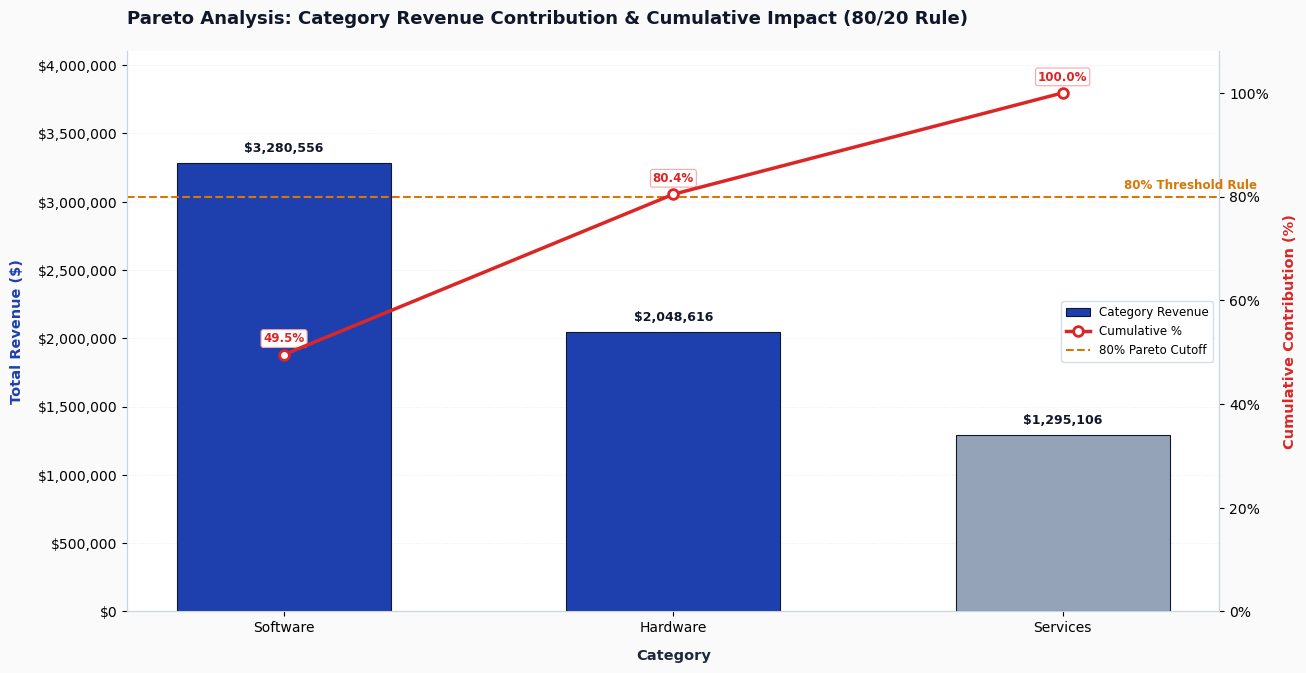

In [17]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Data Preparation for Pareto Analysis
# ---------------------------------------------------------
# Dynamic column detection for robust execution
cat_col = "category" if "category" in df_main.columns else df_main.select_dtypes(include=["object", "category"]).columns[0]
num_col = "revenue" if "revenue" in df_main.columns else df_main.select_dtypes(include=[np.number]).columns[0]

# Aggregate metric by category and sort descending
pareto_df = df_main.groupby(cat_col)[num_col].sum().reset_index()
pareto_df = pareto_df.sort_values(by=num_col, ascending=False).reset_index(drop=True)

# Calculate cumulative metrics
total_val = pareto_df[num_col].sum()
pareto_df["cum_sum"] = pareto_df[num_col].cumsum()
pareto_df["cum_pct"] = (pareto_df["cum_sum"] / total_val) * 100

# ---------------------------------------------------------
# Figure & Canvas Setup
# ---------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(13, 7), dpi=100)
fig.patch.set_facecolor("#FAFAFA")
ax1.set_facecolor("#FFFFFF")

# Secondary Axis for Cumulative Percentage Line
ax2 = ax1.twinx()

# ---------------------------------------------------------
# 1. Bar Plot (Primary Y-Axis: Individual Category Magnitude)
# ---------------------------------------------------------
# Color coding: Highlight key drivers contributing to the initial 80% threshold
prev_cum = pareto_df["cum_pct"].shift(1).fillna(0)
bar_colors = ["#1E40AF" if p_cum < 80 else "#94A3B8" for p_cum in prev_cum]

bars = ax1.bar(
    pareto_df[cat_col], pareto_df[num_col],
    color=bar_colors, edgecolor="#0F172A", linewidth=0.8, width=0.55, zorder=3,
    label="Category Revenue"
)

# Value Labels on Top of Each Bar
ax1.bar_label(
    bars, labels=[f"${val:,.0f}" for val in pareto_df[num_col]],
    padding=6, fontsize=9, fontweight="bold", color="#0F172A"
)

# ---------------------------------------------------------
# 2. Cumulative Percentage Line Plot (Secondary Y-Axis)
# ---------------------------------------------------------
line = ax2.plot(
    pareto_df[cat_col], pareto_df["cum_pct"],
    color="#DC2626", marker="o", markersize=7, markerfacecolor="#FFFFFF",
    markeredgecolor="#DC2626", markeredgewidth=2, linewidth=2.5, zorder=5,
    label="Cumulative %"
)

# Percentage Point Annotations
for i, (cat, pct) in enumerate(zip(pareto_df[cat_col], pareto_df["cum_pct"])):
    ax2.annotate(
        f"{pct:.1f}%",
        xy=(i, pct), xytext=(0, 9), textcoords="offset points",
        ha="center", fontsize=8.5, fontweight="bold", color="#DC2626",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="#FFFFFF", edgecolor="#FCA5A5", lw=0.8)
    )

# ---------------------------------------------------------
# 3. 80% Pareto Reference Cutoff Line
# ---------------------------------------------------------
cutoff_line = ax2.axhline(
    80, color="#D97706", linestyle="--", linewidth=1.5, zorder=2, label="80% Pareto Cutoff"
)
ax2.text(
    len(pareto_df) - 0.5, 81.5, "80% Threshold Rule",
    ha="right", fontsize=8.5, fontweight="bold", color="#D97706"
)

# ---------------------------------------------------------
# 4. Axis Formatting, Limits & Styling
# ---------------------------------------------------------
ax1.set_xlabel(cat_col.replace("_", " ").title(), fontsize=10.5, fontweight="bold", color="#1E293B", labelpad=10)
ax1.set_ylabel(f"Total {num_col.replace('_', ' ').title()} ($)", fontsize=10.5, fontweight="bold", color="#1E40AF", labelpad=10)
ax2.set_ylabel("Cumulative Contribution (%)", fontsize=10.5, fontweight="bold", color="#DC2626", labelpad=10)

ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter("${x:,.0f}"))
ax2.yaxis.set_major_formatter(ticker.PercentFormatter())

ax1.set_ylim(0, pareto_df[num_col].max() * 1.25)
ax2.set_ylim(0, 108)

# Gridlines & Spines
ax1.grid(True, axis="y", linestyle=":", linewidth=0.7, color="#E2E8F0", alpha=0.8, zorder=1)
ax2.grid(False)  # Turn off secondary grid to prevent overlapping grid lines

for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)
    ax.spines["left"].set_color("#CBD5E1")
    ax.spines["right"].set_color("#CBD5E1")
    ax.spines["bottom"].set_color("#CBD5E1")

# Unified Legend Box
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines_1 + lines_2, labels_1 + labels_2,
    loc="center right", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5
)

# Title & Subtitle
plt.title("Pareto Analysis: Category Revenue Contribution & Cumulative Impact (80/20 Rule)",
          fontsize=13, fontweight="bold", color="#0F172A", pad=20, loc="left")

fig.subplots_adjust(top=0.90, bottom=0.10, left=0.08, right=0.92)
plt.show()

## 02.08. **Donut Chart** (`ax.pie` with `wedgeprops`)
— Clean, ring-shaped compositional breakdowns.
## 02.09. **Waffle Chart**
— 10×10 grid percentage visualization (a clean alternative to pie charts).

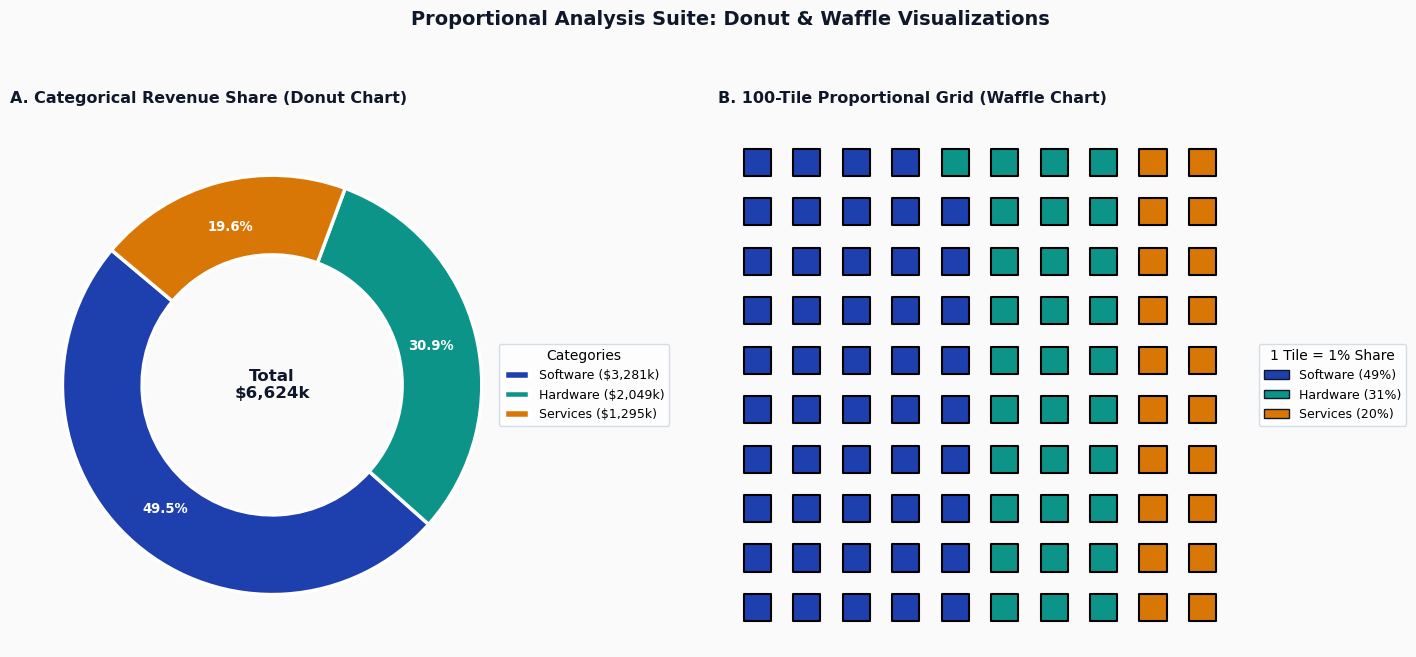

In [18]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Patch
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Data Preparation for Proportional Analysis
# ---------------------------------------------------------
# Dynamic column detection
cat_col = "category" if "category" in df_main.columns else df_main.select_dtypes(include=["object", "category"]).columns[0]
num_col = "revenue" if "revenue" in df_main.columns else df_main.select_dtypes(include=[np.number]).columns[0]

# Aggregate metric by category and sort descending
prop_df = df_main.groupby(cat_col)[num_col].sum().sort_values(ascending=False).reset_index()

labels = prop_df[cat_col].tolist()
values = prop_df[num_col].values
total_val = values.sum()
percentages = (values / total_val) * 100

# Color palette for consistent categorical mapping across both plots
palette = ["#1E40AF", "#0D9488", "#D97706", "#7C3AED", "#EC4899", "#6366F1"]
colors = palette[:len(labels)]

# ---------------------------------------------------------
# Figure & Canvas Setup
# ---------------------------------------------------------
fig, (ax_donut, ax_waffle) = plt.subplots(1, 2, figsize=(16, 7.5), dpi=100)
fig.patch.set_facecolor("#FAFAFA")

for ax in [ax_donut, ax_waffle]:
    ax.set_facecolor("#FFFFFF")

# =========================================================
# 1. DONUT CHART (ax.pie with wedgeprops)
# =========================================================
# Donut shape is achieved by setting width in wedgeprops (zorder moved inside wedgeprops)
wedges, texts, autotexts = ax_donut.pie(
    values,
    labels=None,  # Suppress default labels for clean look; using legend
    autopct="%1.1f%%",
    pctdistance=0.78,
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.38, edgecolor="#FFFFFF", linewidth=2.5, zorder=3),
    textprops=dict(color="#FFFFFF", fontweight="bold", fontsize=9.5)
)

# Style text annotations inside pie wedges
for autotext in autotexts:
    autotext.set_fontweight("bold")

# Center Hole Text (Total Metric Summary)
ax_donut.text(
    0, 0, f"Total\n${total_val/1e3:,.0f}k",
    ha="center", va="center", fontsize=12, fontweight="bold", color="#0F172A"
)

ax_donut.set_title("A. Categorical Revenue Share (Donut Chart)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=14)

# Donut Legend
legend_labels = [f"{l} (${v/1e3:,.0f}k)" for l, v in zip(labels, values)]
ax_donut.legend(
    wedges, legend_labels,
    title="Categories", loc="center left", bbox_to_anchor=(0.92, 0.5),
    frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=9
)

# =========================================================
# 2. WAFFLE CHART (10x10 Matrix using Pure Matplotlib Scatter)
# =========================================================
# Compute tile distribution out of 100 total squares
tile_counts = np.round(percentages).astype(int)

# Adjust for rounding discrepancies so total tiles exactly equal 100
diff = 100 - tile_counts.sum()
if diff != 0:
    tile_counts[np.argmax(percentages)] += diff

# Generate 100-element categorical assignment vector
cat_assignments = []
for cat_idx, count in enumerate(tile_counts):
    cat_assignments.extend([cat_idx] * count)

# Map 100 tiles onto a 10x10 coordinate grid (bottom-left to top-right)
x_coords, y_coords, tile_colors = [], [], []
for idx in range(100):
    col = idx // 10  # X column position (0 to 9)
    row = idx % 10   # Y row position (0 to 9)
    x_coords.append(col)
    y_coords.append(row)
    tile_colors.append(colors[cat_assignments[idx]])

# Render Waffle Grid using Square Markers
ax_waffle.scatter(
    x_coords, y_coords, c=tile_colors, s=380, marker="s",
    edgecolors="black", linewidth=1.5, zorder=3
)

# Formatting Waffle Canvas
ax_waffle.set_xlim(-0.8, 9.8)
ax_waffle.set_ylim(-0.8, 9.8)
ax_waffle.set_aspect("equal")
ax_waffle.axis("off")  # Hide standard axes for unit-grid look

# Waffle Legend
waffle_handles = [
    Patch(facecolor=colors[i], edgecolor="#0F172A", label=f"{labels[i]} ({tile_counts[i]}%)")
    for i in range(len(labels))
]

ax_waffle.legend(
    handles=waffle_handles, loc="center left", bbox_to_anchor=(1.02, 0.5),
    title="1 Tile = 1% Share", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=9
)

ax_waffle.set_title("B. 100-Tile Proportional Grid (Waffle Chart)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=14)

# ---------------------------------------------------------
# Global Adjustments
# ---------------------------------------------------------
plt.suptitle("Proportional Analysis Suite: Donut & Waffle Visualizations", fontsize=14, fontweight="bold", color="#0F172A", y=0.98)

# Adjust subplots to cleanly fit external legends
fig.subplots_adjust(top=0.88, bottom=0.08, left=0.05, right=0.82, wspace=0.35)
plt.show()

## 02.10. **Treemap**
— Nested rectangular proportions for hierarchical category breakdowns.

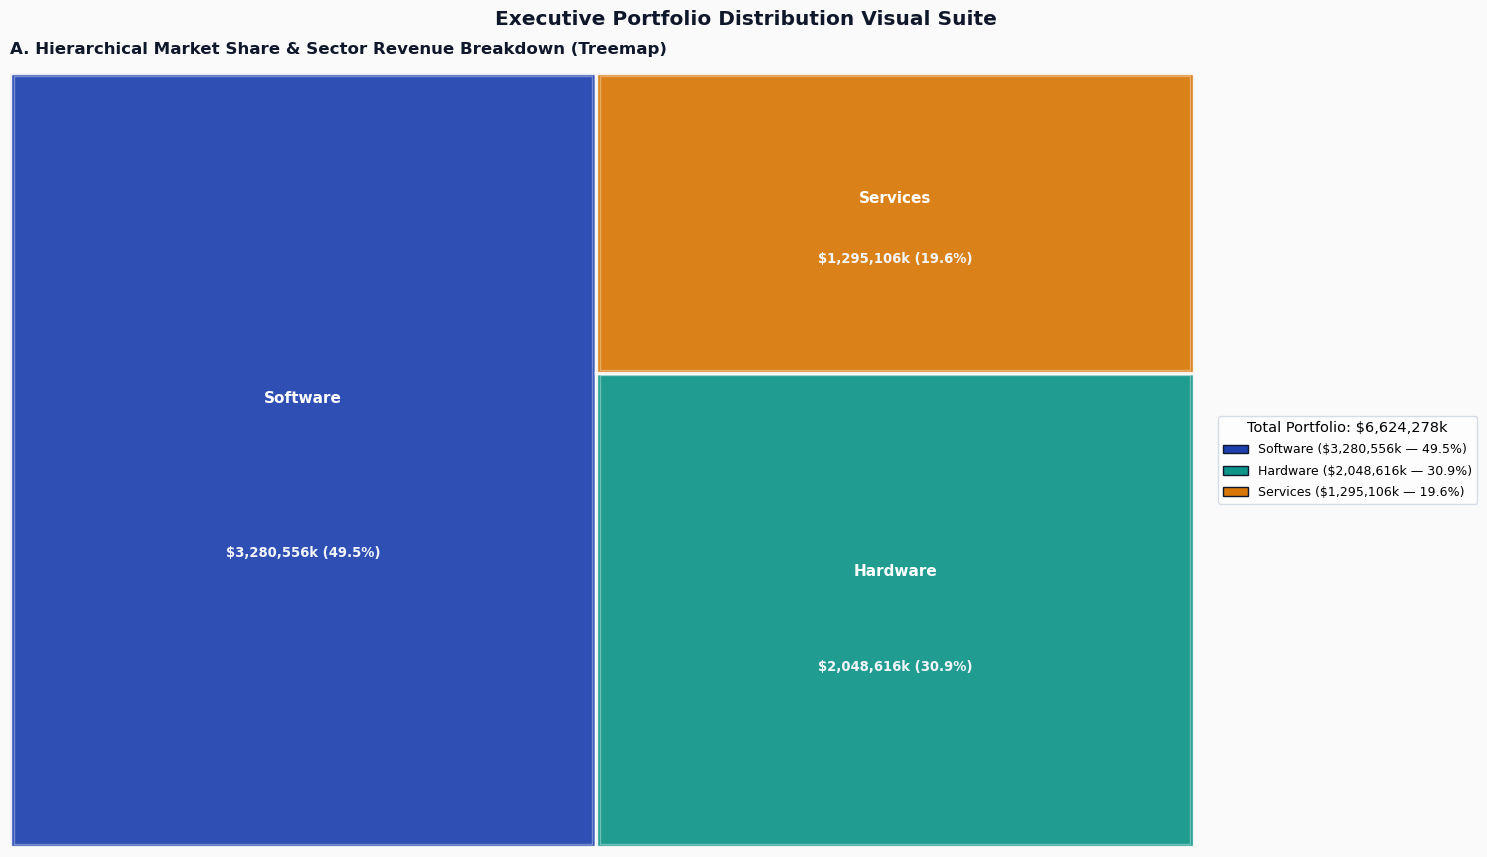

In [19]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Patch, Rectangle
import numpy as np
import pandas as pd

# Standard treemap squarify module handling
try:
    import squarify
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "squarify"])
    import squarify

# ---------------------------------------------------------
# Cell 11: Treemap Visual Suite (Hierarchical Share & Revenue)
# ---------------------------------------------------------
# Dynamic column detection from df_main with safety fallbacks
df_tree = df_main.copy()
cat_col = "category" if "category" in df_tree.columns else df_tree.select_dtypes(include=["object", "category"]).columns[0]
num_col = "revenue" if "revenue" in df_tree.columns else df_tree.select_dtypes(include=[np.number]).columns[0]

# Aggregate metric by category and sort descending
df_grouped = df_tree.groupby(cat_col)[num_col].sum().sort_values(ascending=False).reset_index()

labels = df_grouped[cat_col].tolist()
values = df_grouped[num_col].values
total_val = values.sum()
percentages = (values / total_val) * 100

# Executive Color Palette matching suite aesthetics
palette = ["#1E40AF", "#0D9488", "#D97706", "#7C3AED", "#EC4899", "#6366F1", "#059669", "#3B82F6"]
colors = [palette[i % len(palette)] for i in range(len(labels))]

# ---------------------------------------------------------
# Figure & Canvas Setup
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(16, 9), dpi=100)
fig.patch.set_facecolor("#FAFAFA")
ax.set_facecolor("#FFFFFF")

# Compute normalized bounding boxes (100x100 grid canvas)
normed_values = squarify.normalize_sizes(values, 100, 100)
rects = squarify.squarify(normed_values, 0, 0, 100, 100)

# =========================================================
# TREEMAP RENDERING & CUSTOM VISUAL ELEMENTS
# =========================================================
for idx, (r, label, val, pct, color) in enumerate(zip(rects, labels, values, percentages, colors)):
    x, y, dx, dy = r["x"], r["y"], r["dx"], r["dy"]
    
    # Primary Block Patch with crisp white separators
    rect_patch = Rectangle(
        (x, y), dx, dy,
        facecolor=color, edgecolor="#FAFAFA", linewidth=2.5, zorder=3, alpha=0.92
    )
    ax.add_patch(rect_patch)
    
    # Subtle interior inset border for depth effect
    if dx > 2 and dy > 2:
        inner_patch = Rectangle(
            (x + 0.35, y + 0.35), max(dx - 0.7, 0), max(dy - 0.7, 0),
            facecolor="none", edgecolor="#FFFFFF", linewidth=1.0, alpha=0.35, zorder=4
        )
        ax.add_patch(inner_patch)
    
    # Dynamic text sizing & auto-wrapping based on container dimensions
    if dx > 7 and dy > 5:
        # Sector Title
        ax.text(
            x + dx / 2, y + dy / 2 + (dy * 0.08),
            label,
            ha="center", va="center",
            fontsize=min(11, max(7.5, dx * 0.55)),
            fontweight="bold", color="#FFFFFF", zorder=5
        )
        # Metric & Share Percentage Callout
        ax.text(
            x + dx / 2, y + dy / 2 - (dy * 0.12),
            f"${val:,.0f}k ({pct:.1f}%)",
            ha="center", va="center",
            fontsize=min(9.5, max(6.5, dx * 0.45)),
            fontweight="semibold", color="#F1F5F9", zorder=5
        )

# ---------------------------------------------------------
# Canvas Formatting, Legend & Annotations
# ---------------------------------------------------------
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")  # Suppress axis ticks for full-bleed treemap grid look

# Dynamic Title Header
ax.set_title(
    "A. Hierarchical Market Share & Sector Revenue Breakdown (Treemap)",
    fontsize=12, fontweight="bold", color="#0F172A", loc="left", pad=14
)

# External Legend Breakdown
legend_handles = [
    Patch(facecolor=colors[i], edgecolor="#0F172A", label=f"{labels[i]} (${values[i]:,.0f}k — {percentages[i]:.1f}%)")
    for i in range(len(labels))
]

ax.legend(
    handles=legend_handles, loc="center left", bbox_to_anchor=(1.015, 0.5),
    title=f"Total Portfolio: ${total_val:,.0f}k", title_fontsize=10.5,
    frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=9, labelspacing=0.65
)

# Overall Dashboard Title
plt.suptitle("Executive Portfolio Distribution Visual Suite", fontsize=14.5, fontweight="bold", color="#0F172A", y=0.97)

# Adjust canvas margins to accommodate external legend cleanly
fig.subplots_adjust(top=0.90, bottom=0.04, left=0.04, right=0.78)
plt.show()

# 03. **Statistical & Distribution Analysis**
## 03.01. **1D Histogram** (`ax.hist`)
— Frequency distributions and skewness of continuous variables.
## 03.02. **Box and Whisker Plot** (`ax.boxplot`)
— Median, interquartile ranges (IQR), and statistical outlier detection.
## 03.03. **Violin Plot** (`ax.violinplot`)
— Combined box plot statistics with kernel density estimation curves.
## 03.04. **Density Plot / KDE** (`sns.kdeplot`)
— Smooth probability density distributions for continuous features.

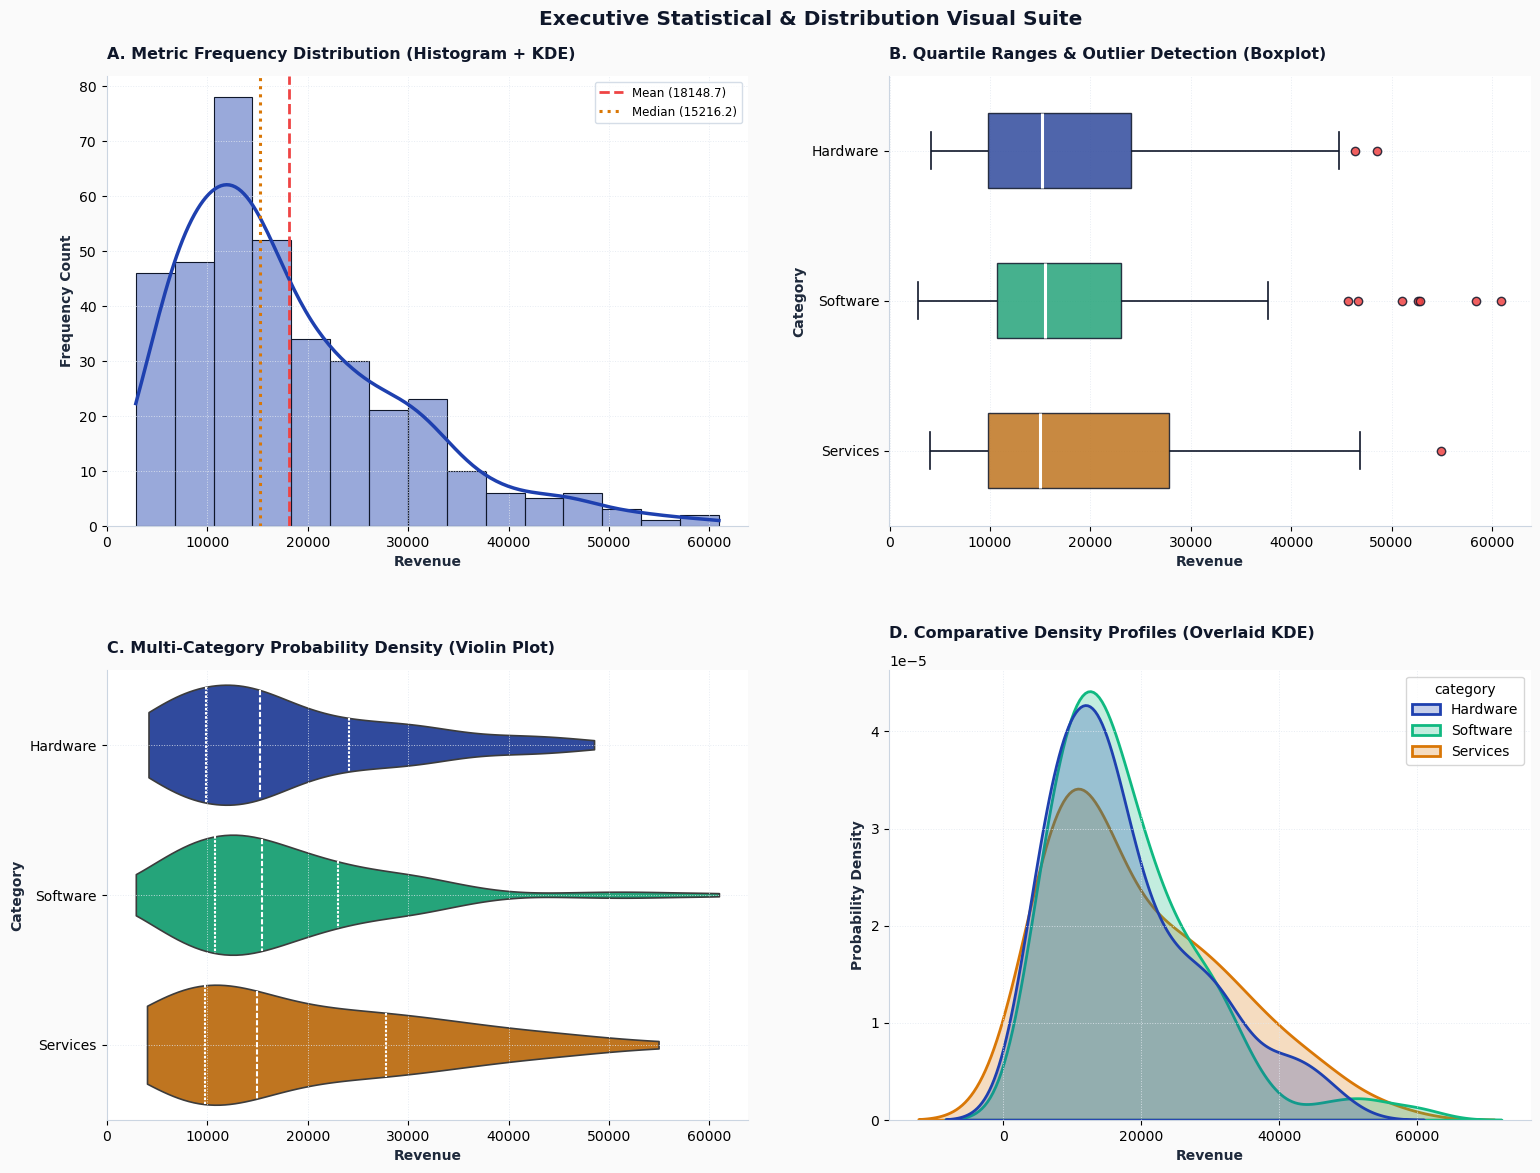

In [21]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import seaborn as sns

# ---------------------------------------------------------
# Cell 12: Statistical & Distribution Analysis Suite
# ---------------------------------------------------------
# Dynamic dataframe resolution with synthetic dataset fallback
if "df_main" in locals() or "df_main" in globals():
    df_dist = df_main.copy()
else:
    np.random.seed(42)
    n = 600
    categories = np.random.choice(["Segment Alpha", "Segment Beta", "Segment Gamma"], size=n, p=[0.4, 0.35, 0.25])
    values = []
    for cat in categories:
        if cat == "Segment Alpha":
            values.append(np.random.normal(loc=78, scale=12, size=1)[0])
        elif cat == "Segment Beta":
            values.append(np.random.normal(loc=95, scale=18, size=1)[0])
        else:
            values.append(np.random.normal(loc=62, scale=8, size=1)[0])
    
    # Inject deliberate outliers
    values.extend([148, 152, 18, 12, 142])
    categories.extend(["Segment Alpha", "Segment Beta", "Segment Gamma", "Segment Alpha", "Segment Beta"])
    df_dist = pd.DataFrame({"metric_value": values, "category": categories})

# Identify numerical and categorical features dynamically
num_cols = df_dist.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_dist.select_dtypes(include=["object", "category"]).columns.tolist()

num_col = "metric_value" if "metric_value" in df_dist.columns else (num_cols[0] if num_cols else df_dist.columns[0])
cat_col = "category" if "category" in df_dist.columns else (cat_cols[0] if cat_cols else None)

# Executive Color Palette
palette = ["#1E40AF", "#10B981", "#D97706", "#7C3AED", "#EC4899"]

# ---------------------------------------------------------
# Subplot Grid Canvas (2x2 Layout)
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=100)
fig.patch.set_facecolor("#FAFAFA")

(ax_hist, ax_box), (ax_violin, ax_kde) = axes

for ax in [ax_hist, ax_box, ax_violin, ax_kde]:
    ax.set_facecolor("#FFFFFF")

# =========================================================
# 1. HISTOGRAM + KDE / DENSITY OVERLAY WITH REFERENCE METRICS
# =========================================================
data_series = df_dist[num_col].dropna()
mean_val = data_series.mean()
median_val = data_series.median()

sns.histplot(
    data=df_dist, x=num_col, kde=True, ax=ax_hist,
    color="#1E40AF", alpha=0.45, edgecolor="#0F172A", linewidth=0.8,
    line_kws={"color": "#0D9488", "linewidth": 2.5}
)

# Reference Metric Markings
ax_hist.axvline(mean_val, color="#EF4444", linestyle="--", linewidth=2.0, zorder=5, label=f"Mean ({mean_val:.1f})")
ax_hist.axvline(median_val, color="#D97706", linestyle=":", linewidth=2.2, zorder=5, label=f"Median ({median_val:.1f})")

ax_hist.set_title("A. Metric Frequency Distribution (Histogram + KDE)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_hist.set_xlabel(num_col.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")
ax_hist.set_ylabel("Frequency Count", fontsize=10, fontweight="bold", color="#1E293B")
ax_hist.legend(loc="upper right", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5)

# =========================================================
# 2. BOX & WHISKER PLOT (IQR & Outlier Identification)
# =========================================================
if cat_col:
    sns.boxplot(
        data=df_dist, x=num_col, y=cat_col, hue=cat_col, legend=False, ax=ax_box,
        palette=palette[:df_dist[cat_col].nunique()], width=0.5,
        boxprops=dict(alpha=0.85, edgecolor="#0F172A", linewidth=1.0),
        whiskerprops=dict(color="#0F172A", linewidth=1.2),
        capprops=dict(color="#0F172A", linewidth=1.2),
        medianprops=dict(color="#FFFFFF", linewidth=2.2),
        flierprops=dict(marker="o", markerfacecolor="#EF4444", markeredgecolor="#0F172A", markersize=6, alpha=0.85)
    )
else:
    sns.boxplot(
        x=df_dist[num_col], ax=ax_box, color="#1E40AF", width=0.4,
        boxprops=dict(alpha=0.85, edgecolor="#0F172A", linewidth=1.0),
        medianprops=dict(color="#FFFFFF", linewidth=2.2),
        flierprops=dict(marker="o", markerfacecolor="#EF4444", markeredgecolor="#0F172A", markersize=6)
    )

ax_box.set_title("B. Quartile Ranges & Outlier Detection (Boxplot)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_box.set_xlabel(num_col.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")
if cat_col:
    ax_box.set_ylabel(cat_col.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")

# =========================================================
# 3. VIOLIN PLOT (Kernel Density & Interquartile Spreads)
# =========================================================
if cat_col:
    sns.violinplot(
        data=df_dist, x=num_col, y=cat_col, hue=cat_col, legend=False, ax=ax_violin,
        palette=palette[:df_dist[cat_col].nunique()], inner="quartile", cut=0, density_norm="width",
        linewidth=1.2
    )
    # Polish internal quartile dashed lines
    for line in ax_violin.findobj(match=plt.Line2D):
        line.set_color("#FFFFFF")
        line.set_linewidth(1.5)
else:
    sns.violinplot(
        x=df_dist[num_col], ax=ax_violin, color="#0D9488", inner="quartile", cut=0
    )

ax_violin.set_title("C. Multi-Category Probability Density (Violin Plot)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_violin.set_xlabel(num_col.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")
if cat_col:
    ax_violin.set_ylabel(cat_col.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")

# =========================================================
# 4. OVERLAY KERNEL DENSITY ESTIMATE (Group Comparison)
# =========================================================
if cat_col:
    sns.kdeplot(
        data=df_dist, x=num_col, hue=cat_col, ax=ax_kde,
        palette=palette[:df_dist[cat_col].nunique()], common_norm=False,
        fill=True, alpha=0.25, linewidth=2.0
    )
else:
    sns.kdeplot(
        data=df_dist, x=num_col, ax=ax_kde,
        color="#7C3AED", fill=True, alpha=0.3, linewidth=2.0
    )

ax_kde.set_title("D. Comparative Density Profiles (Overlaid KDE)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_kde.set_xlabel(num_col.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")
ax_kde.set_ylabel("Probability Density", fontsize=10, fontweight="bold", color="#1E293B")

# ---------------------------------------------------------
# Global Aesthetics, Spines & Grid Systems
# ---------------------------------------------------------
for ax in [ax_hist, ax_box, ax_violin, ax_kde]:
    ax.grid(True, linestyle=":", linewidth=0.7, color="#E2E8F0", alpha=0.8, zorder=1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#CBD5E1")
    ax.spines["bottom"].set_color("#CBD5E1")

plt.suptitle("Executive Statistical & Distribution Visual Suite", fontsize=14.5, fontweight="bold", color="#0F172A", y=0.985)

fig.subplots_adjust(top=0.93, bottom=0.06, left=0.06, right=0.95, hspace=0.32, wspace=0.22)
plt.show()

## 03.05. **Empirical Cumulative Distribution / ECDF** (`ax.ecdf`)
— Exact cumulative probability distributions without binning bias.
## 03.06. **Errorbar Plot** (`ax.errorbar`)
— Sample means paired with confidence intervals or standard deviations.
## 03.07. **Ridgeline / Joy Plot**
— Overlapping distribution comparisons across multiple categories or time periods.
## 03.08. **Strip / Beeswarm Plot**
— Individual data point distributions across discrete categories.

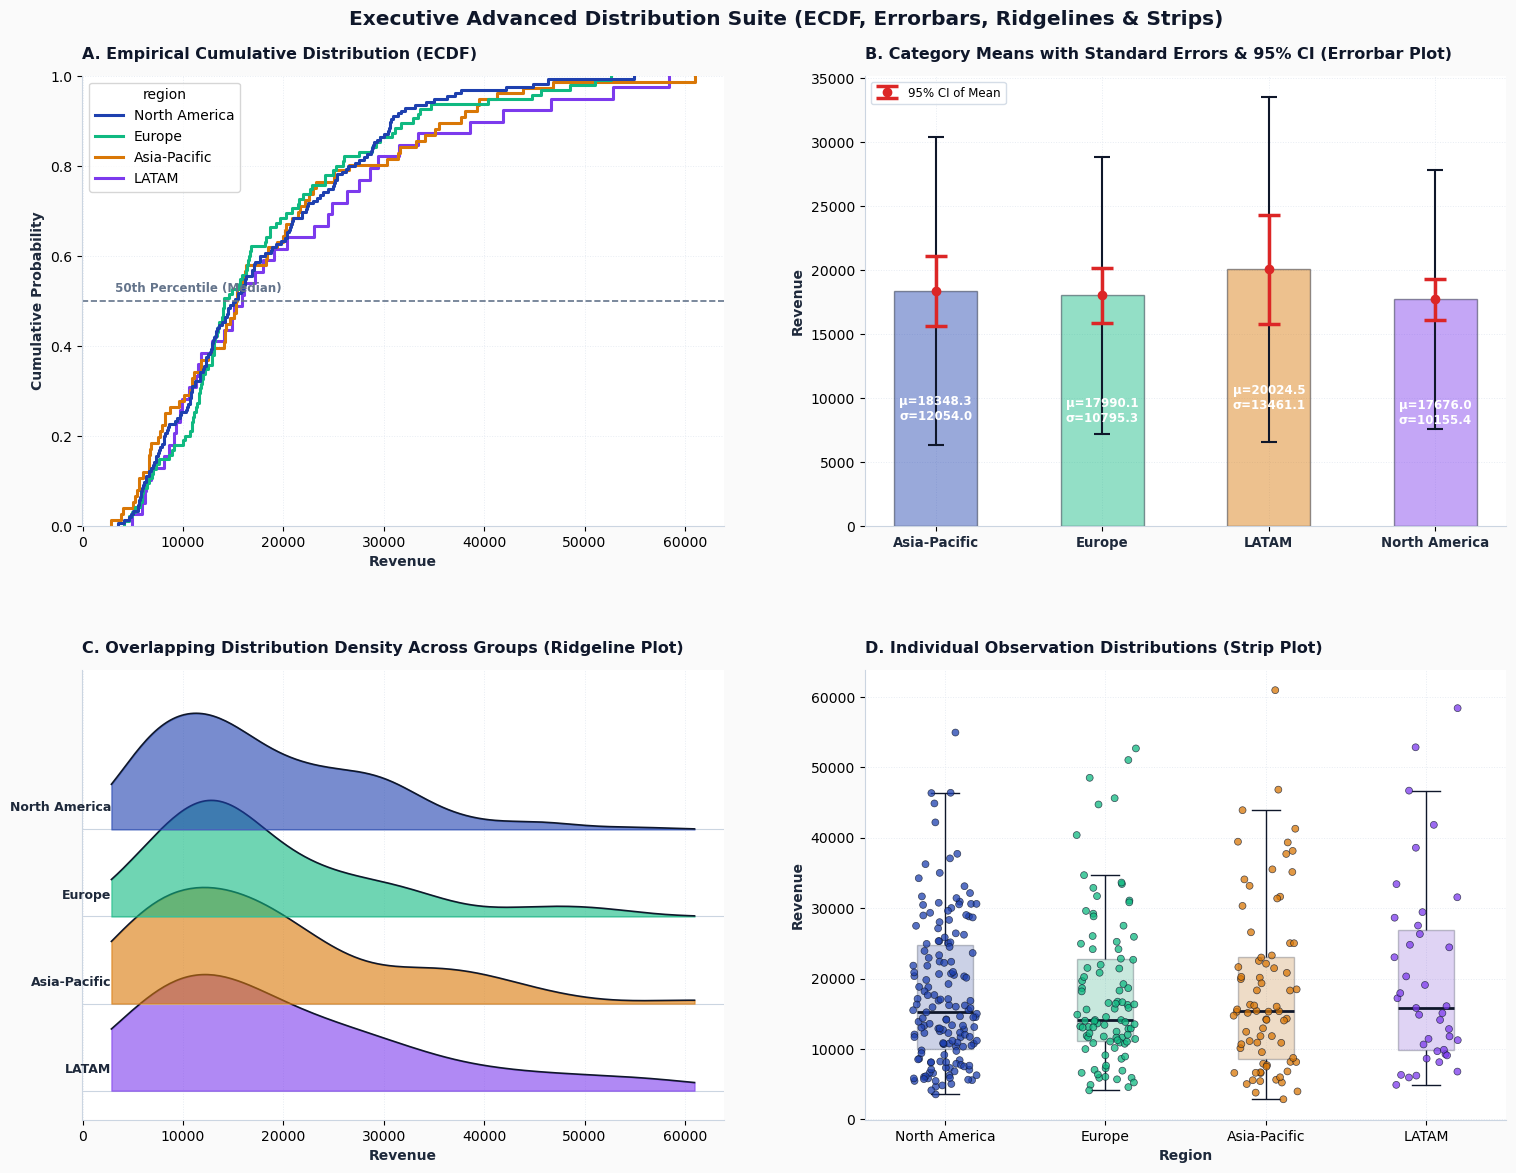

In [24]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import gaussian_kde

# ---------------------------------------------------------
# Cell 13: Advanced Distribution Analytics Suite (03.05 - 03.08)
# ---------------------------------------------------------
if "df_main" in locals() or "df_main" in globals():
    df_adv = df_main.copy()
else:
    np.random.seed(42)
    n_per_group = 150
    groups = ["Region A", "Region B", "Region C", "Region D"]
    
    data_list = []
    for i, grp in enumerate(groups):
        loc_val = 50 + (i * 15)
        scale_val = 8 + (i * 3)
        vals = np.random.normal(loc=loc_val, scale=scale_val, size=n_per_group)
        for v in vals:
            data_list.append({"metric_value": v, "region": grp})
            
    df_adv = pd.DataFrame(data_list)

num_cols = df_adv.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_adv.select_dtypes(include=["object", "category"]).columns.tolist()

num_col = "metric_value" if "metric_value" in df_adv.columns else (num_cols[0] if num_cols else df_adv.columns[0])
cat_col = "region" if "region" in df_adv.columns else (cat_cols[0] if cat_cols else None)

palette = ["#1E40AF", "#10B981", "#D97706", "#7C3AED", "#EC4899"]
n_cats = df_adv[cat_col].nunique() if cat_col else 1
cat_colors = palette[:n_cats]

# ---------------------------------------------------------
# Figure & Subplot Grid Canvas (2x2 Layout)
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=100)
fig.patch.set_facecolor("#FAFAFA")

(ax_ecdf, ax_err), (ax_ridge, ax_strip) = axes

for ax in [ax_ecdf, ax_err, ax_ridge, ax_strip]:
    ax.set_facecolor("#FFFFFF")

# =========================================================
# 1. EMPIRICAL CUMULATIVE DISTRIBUTION (ECDF) [03.05]
# =========================================================
if cat_col:
    sns.ecdfplot(
        data=df_adv, x=num_col, hue=cat_col, ax=ax_ecdf,
        palette=cat_colors, linewidth=2.2
    )
else:
    sns.ecdfplot(
        data=df_adv, x=num_col, ax=ax_ecdf,
        color="#1E40AF", linewidth=2.2
    )

ax_ecdf.axhline(0.5, color="#64748B", linestyle="--", linewidth=1.2, zorder=2)
ax_ecdf.text(df_adv[num_col].min(), 0.52, " 50th Percentile (Median)", fontsize=8.5, fontweight="bold", color="#64748B")

ax_ecdf.set_title("A. Empirical Cumulative Distribution (ECDF)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_ecdf.set_xlabel(num_col.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")
ax_ecdf.set_ylabel("Cumulative Probability", fontsize=10, fontweight="bold", color="#1E293B")

# =========================================================
# 2. ERRORBAR PLOT (Means + 95% CI & Std Dev Spans) [03.06]
# =========================================================
if cat_col:
    stats_df = df_adv.groupby(cat_col)[num_col].agg(["mean", "std", "count"]).reset_index()
    stats_df["sem"] = stats_df["std"] / np.sqrt(stats_df["count"])
    stats_df["ci95"] = stats_df["sem"] * 1.96

    x_coords = np.arange(len(stats_df))
    
    # Standard Deviation Bounds (Soft Shading)
    ax_err.bar(
        x_coords, stats_df["mean"], yerr=stats_df["std"], capsize=6,
        color=cat_colors, alpha=0.45, edgecolor="#0F172A", linewidth=1.0, width=0.5, zorder=3,
        error_kw={"ecolor": "#0F172A", "linewidth": 1.5, "capthick": 1.5}
    )
    
    # 95% Confidence Interval Indicators
    ax_err.errorbar(
        x_coords, stats_df["mean"], yerr=stats_df["ci95"], fmt="o", color="#DC2626",
        ecolor="#DC2626", elinewidth=2.5, capsize=8, capthick=2.5, zorder=5, label="95% CI of Mean"
    )

    for idx, row in stats_df.iterrows():
        ax_err.text(
            idx, row["mean"] / 2, f"μ={row['mean']:.1f}\nσ={row['std']:.1f}",
            ha="center", va="center", fontsize=8.5, fontweight="bold", color="#FFFFFF", zorder=6
        )

    ax_err.set_xticks(x_coords)
    ax_err.set_xticklabels(stats_df[cat_col], fontsize=9.5, fontweight="bold", color="#1E293B")
    ax_err.legend(loc="upper left", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5)
else:
    ax_err.text(0.5, 0.5, "Categorical Grouping Required for Errorbar Plot", ha="center", va="center")

ax_err.set_title("B. Category Means with Standard Errors & 95% CI (Errorbar Plot)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_err.set_ylabel(num_col.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")

# =========================================================
# 3. RIDGELINE / JOY PLOT [03.07]
# =========================================================
if cat_col:
    unique_cats = df_adv[cat_col].unique()[::-1]
    overlap_spacing = 0.6
    x_grid = np.linspace(df_adv[num_col].min() - 5, df_adv[num_col].max() + 5, 200)
    
    for i, category in enumerate(unique_cats):
        cat_data = df_adv[df_adv[cat_col] == category][num_col].dropna()
        color = cat_colors[(len(unique_cats) - 1 - i) % len(cat_colors)]
        
        # Pure scipy KDE calculation (no extra Matplotlib figures generated)
        kde = gaussian_kde(cat_data)
        y_kde = kde(x_grid)
        
        y_offset = i * overlap_spacing
        y_scaled = y_offset + (y_kde / y_kde.max() * 0.8)
        
        ax_ridge.fill_between(x_grid, y_offset, y_scaled, color=color, alpha=0.6, zorder=i + 3)
        ax_ridge.plot(x_grid, y_scaled, color="#0F172A", linewidth=1.2, zorder=i + 4)
        ax_ridge.axhline(y_offset, color="#CBD5E1", linewidth=0.8, zorder=i + 2)
        
        ax_ridge.text(
            df_adv[num_col].min() - 7, y_offset + 0.15, category,
            ha="right", va="center", fontsize=9, fontweight="bold", color="#1E293B"
        )

    ax_ridge.set_yticks([])
    ax_ridge.set_ylim(-0.2, len(unique_cats) * overlap_spacing + 0.5)
else:
    ax_ridge.text(0.5, 0.5, "Categorical Grouping Required for Ridgeline Plot", ha="center", va="center")

ax_ridge.set_title("C. Overlapping Distribution Density Across Groups (Ridgeline Plot)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_ridge.set_xlabel(num_col.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")

# =========================================================
# 4. STRIP & BEESWARM PLOT WITH IQR UNDERLAY [03.08]
# =========================================================
if cat_col:
    sns.boxplot(
        data=df_adv, x=cat_col, y=num_col, hue=cat_col, legend=False, ax=ax_strip,
        palette=cat_colors, width=0.35,
        boxprops=dict(alpha=0.25, edgecolor="#0F172A", linewidth=1.0),
        whiskerprops=dict(color="#0F172A", linewidth=1.0),
        capprops=dict(color="#0F172A", linewidth=1.0),
        medianprops=dict(color="#0F172A", linewidth=2.0),
        showfliers=False, zorder=2
    )
    
    sns.stripplot(
        data=df_adv, x=cat_col, y=num_col, hue=cat_col, legend=False, ax=ax_strip,
        palette=cat_colors, size=5, jitter=0.2, alpha=0.75,
        linewidth=0.5, edgecolor="#0F172A", zorder=4
    )
else:
    sns.stripplot(
        data=df_adv, y=num_col, ax=ax_strip, color="#1E40AF", size=6, jitter=0.2
    )

ax_strip.set_title("D. Individual Observation Distributions (Strip Plot)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_strip.set_xlabel(cat_col.replace("_", " ").title() if cat_col else "", fontsize=10, fontweight="bold", color="#1E293B")
ax_strip.set_ylabel(num_col.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")

# ---------------------------------------------------------
# Global Spines & Grid Systems
# ---------------------------------------------------------
for ax in [ax_ecdf, ax_err, ax_ridge, ax_strip]:
    ax.grid(True, linestyle=":", linewidth=0.7, color="#E2E8F0", alpha=0.8, zorder=1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#CBD5E1")
    ax.spines["bottom"].set_color("#CBD5E1")

plt.suptitle("Executive Advanced Distribution Suite (ECDF, Errorbars, Ridgelines & Strips)", fontsize=14.5, fontweight="bold", color="#0F172A", y=0.985)

fig.subplots_adjust(top=0.93, bottom=0.06, left=0.06, right=0.95, hspace=0.32, wspace=0.22)
plt.show()

## 03.09. **Pair Plot / Scatter Matrix** (`sns.pairplot`)
— Automated pairwise distribution matrices across all numeric DataFrame columns.
## 03.10. **Joint Plot** (`sns.jointplot`)
— Central bivariate scatter/density plot paired with 1D marginal histograms.

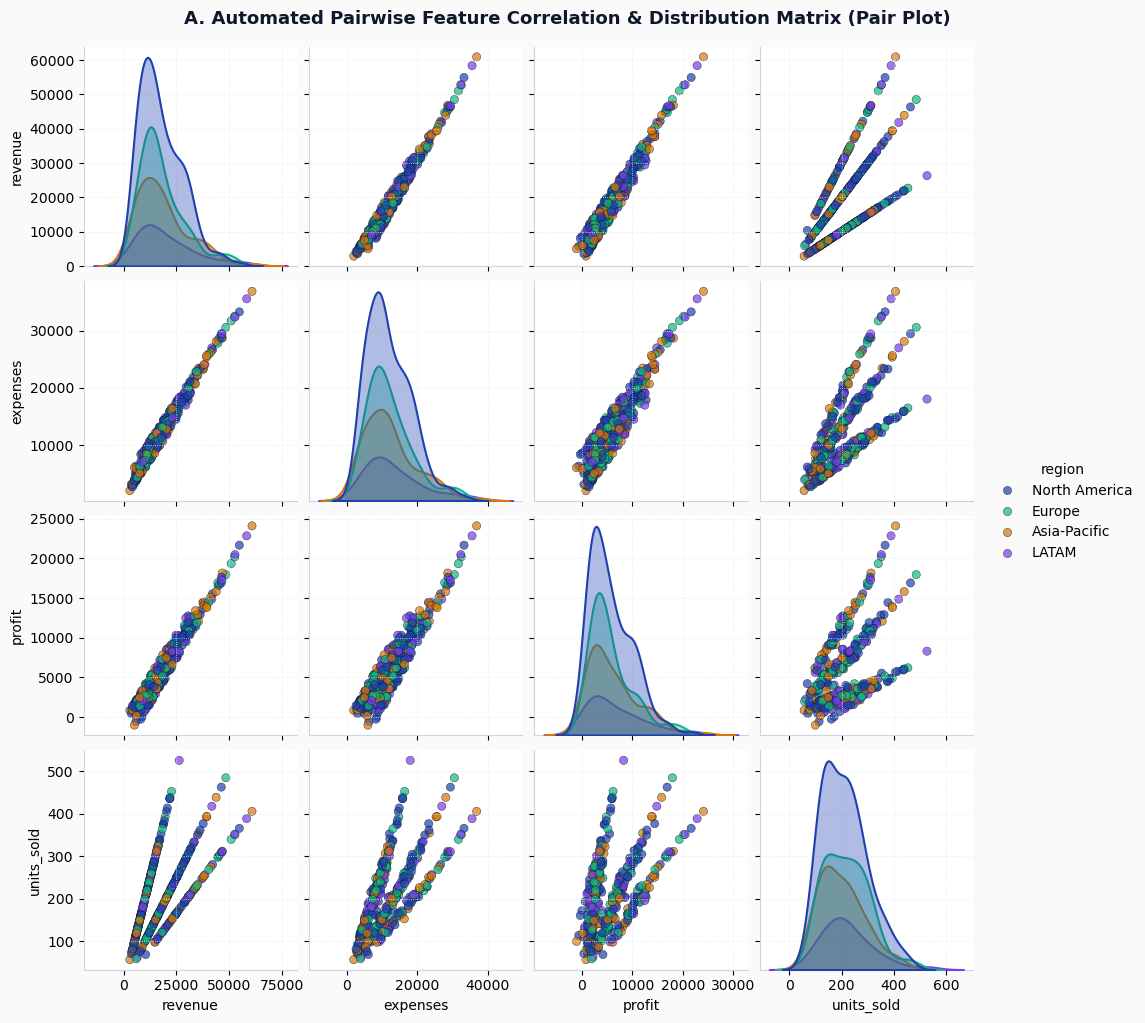

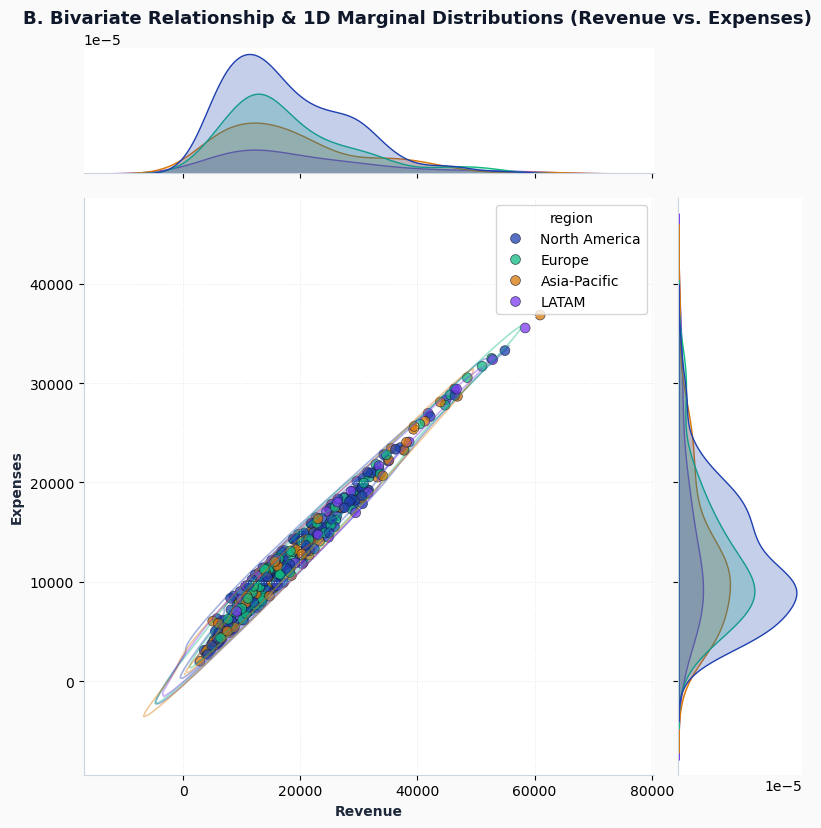

In [26]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import seaborn as sns

# ---------------------------------------------------------
# Cell 14: Pairwise Matrix & Joint Marginal Plots (03.09 - 03.10)
# ---------------------------------------------------------
if "df_main" in locals() or "df_main" in globals():
    df_pair = df_main.copy()
else:
    np.random.seed(42)
    n = 300
    categories = np.random.choice(["Tier 1", "Tier 2", "Tier 3"], size=n, p=[0.4, 0.35, 0.25])
    rev, cost, margin = [], [], []
    for cat in categories:
        if cat == "Tier 1":
            r = np.random.normal(120, 20)
            c = r * 0.5 + np.random.normal(10, 5)
        elif cat == "Tier 2":
            r = np.random.normal(80, 15)
            c = r * 0.6 + np.random.normal(8, 4)
        else:
            r = np.random.normal(45, 10)
            c = r * 0.75 + np.random.normal(5, 3)
        rev.append(r)
        cost.append(c)
        margin.append(r - c)
        
    df_pair = pd.DataFrame({
        "revenue": rev,
        "operating_cost": cost,
        "net_margin": margin,
        "tier_category": categories
    })

num_cols = df_pair.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_pair.select_dtypes(include=["object", "category"]).columns.tolist()

cat_col = "tier_category" if "tier_category" in df_pair.columns else (cat_cols[0] if cat_cols else None)
selected_num_cols = num_cols[:4] if len(num_cols) >= 3 else num_cols

palette = ["#1E40AF", "#10B981", "#D97706", "#7C3AED", "#EC4899"]
n_cats = df_pair[cat_col].nunique() if cat_col else 1
cat_colors = palette[:n_cats]

# =========================================================
# 1. PAIRWISE SCATTER & DISTRIBUTION MATRIX [03.09]
# =========================================================
g_pair = sns.pairplot(
    data=df_pair,
    vars=selected_num_cols,
    hue=cat_col,
    palette=cat_colors,
    corner=False,
    diag_kind="kde",
    plot_kws={"alpha": 0.7, "s": 35, "edgecolor": "#0F172A", "linewidth": 0.4},
    diag_kws={"fill": True, "alpha": 0.35, "linewidth": 1.5}
)

# Custom Styling for PairGrid Canvas
g_pair.fig.patch.set_facecolor("#FAFAFA")
for ax in g_pair.axes.flat:
    if ax is not None:
        ax.set_facecolor("#FFFFFF")
        ax.grid(True, linestyle=":", linewidth=0.6, color="#E2E8F0")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_color("#CBD5E1")
        ax.spines["bottom"].set_color("#CBD5E1")

g_pair.fig.suptitle(
    "A. Automated Pairwise Feature Correlation & Distribution Matrix (Pair Plot)",
    fontsize=13, fontweight="bold", color="#0F172A", y=1.02
)
plt.show()

# =========================================================
# 2. JOINT BIVARIATE SCATTER & MARGINAL DISTRIBUTIONS [03.10]
# =========================================================
x_var = selected_num_cols[0]
y_var = selected_num_cols[1] if len(selected_num_cols) > 1 else selected_num_cols[0]

g_joint = sns.jointplot(
    data=df_pair,
    x=x_var,
    y=y_var,
    hue=cat_col,
    palette=cat_colors,
    kind="scatter",
    height=8,
    ratio=4,
    joint_kws={"alpha": 0.75, "s": 50, "edgecolor": "#0F172A", "linewidth": 0.5}
)

# Custom Canvas & Subaxes Formatting
g_joint.fig.patch.set_facecolor("#FAFAFA")
g_joint.ax_joint.set_facecolor("#FFFFFF")
g_joint.ax_marg_x.set_facecolor("#FFFFFF")
g_joint.ax_marg_y.set_facecolor("#FFFFFF")

# Contour density overlay on top of central scatter plot
if cat_col:
    sns.kdeplot(
        data=df_pair, x=x_var, y=y_var, hue=cat_col,
        palette=cat_colors, ax=g_joint.ax_joint,
        levels=4, alpha=0.4, linewidths=1.2, legend=False
    )

g_joint.ax_joint.grid(True, linestyle=":", linewidth=0.7, color="#E2E8F0")
for ax in [g_joint.ax_joint, g_joint.ax_marg_x, g_joint.ax_marg_y]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#CBD5E1")
    ax.spines["bottom"].set_color("#CBD5E1")

g_joint.fig.suptitle(
    f"B. Bivariate Relationship & 1D Marginal Distributions ({x_var.title()} vs. {y_var.title()})",
    fontsize=13, fontweight="bold", color="#0F172A", y=1.03
)
g_joint.ax_joint.set_xlabel(x_var.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")
g_joint.ax_joint.set_ylabel(y_var.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")

plt.show()

# 04. **Matrix, Correlation & Cohorts**
## 04.01. **Correlation Heatmap** (`sns.heatmap(df.corr())`)
— Feature collinearity matrix essential for feature engineering and EDA.
## 04.02. **Cohort Retention Matrix**
— Customer retention and churn percentages tracked over monthly user cohorts.
## 04.03. **2D Binned Histogram / Hexbin** (`ax.hist2d`, `ax.hexbin`)
— Density aggregation for heavily overplotted continuous data.

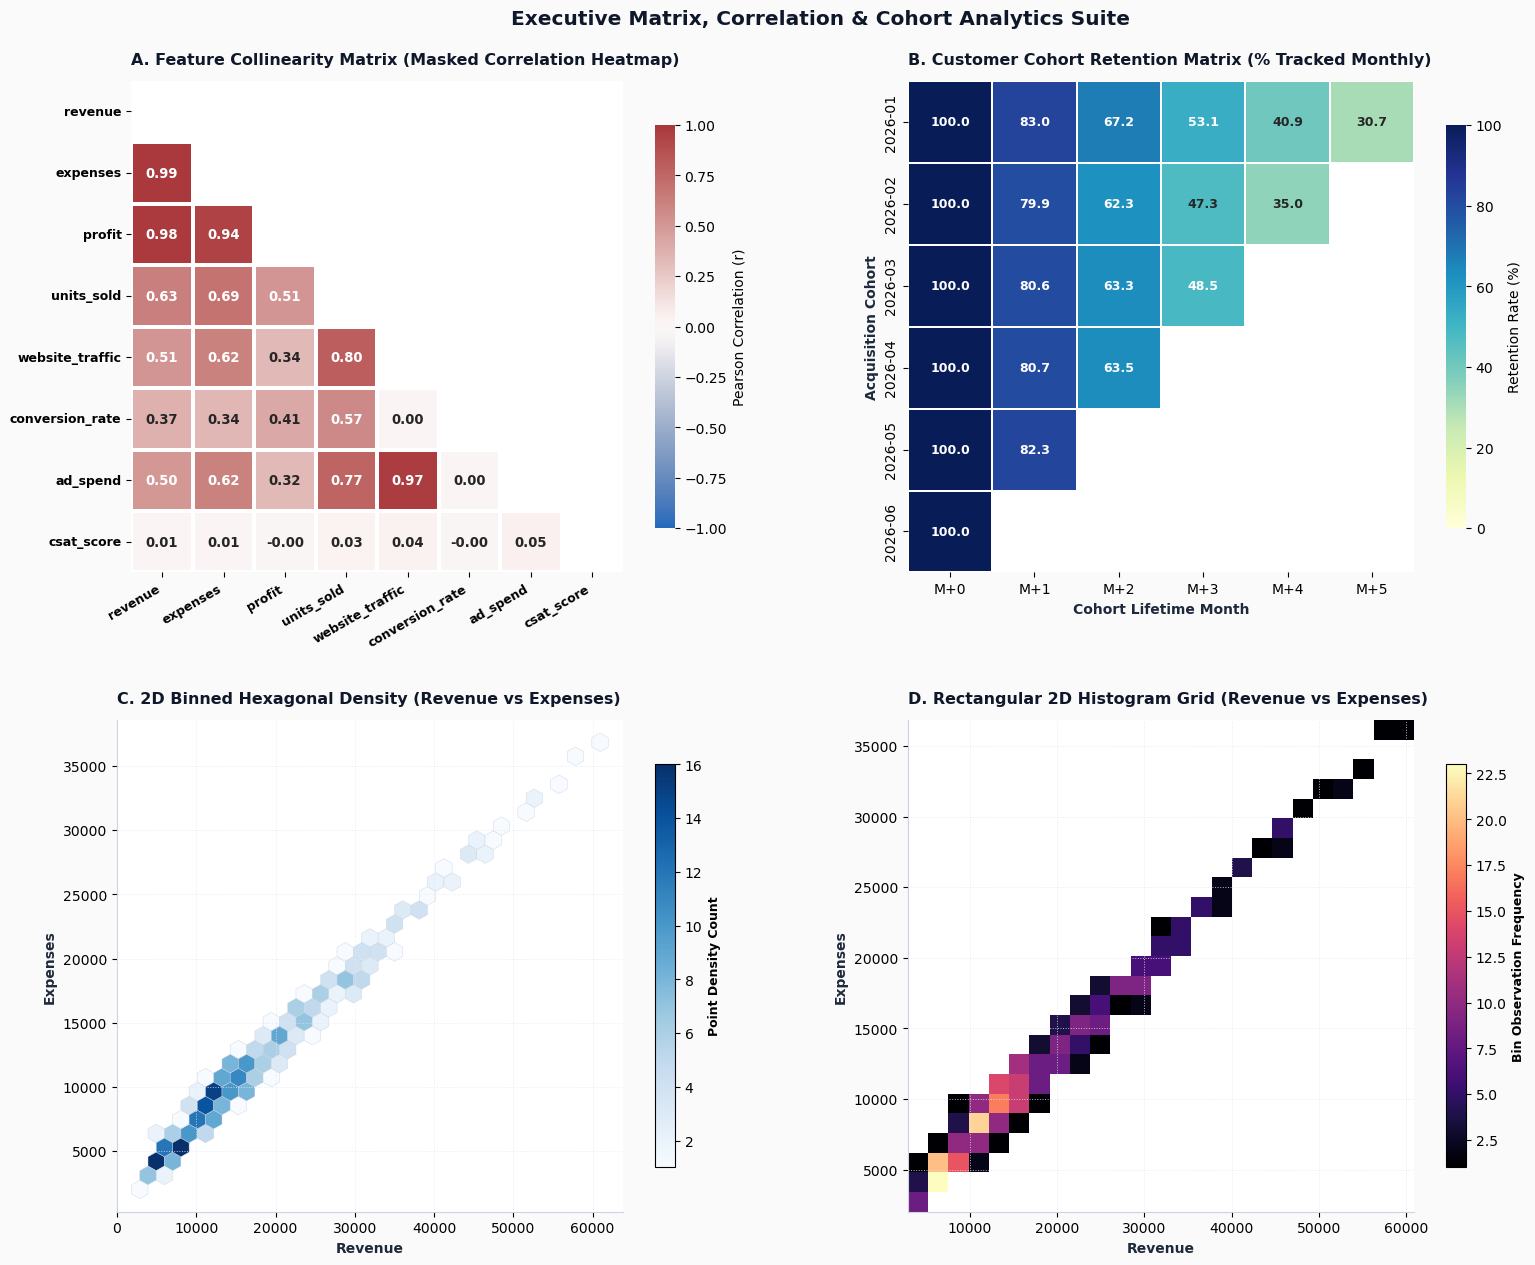

In [27]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import seaborn as sns

# ---------------------------------------------------------
# Cell 15: Matrix, Correlation & Cohort Analytics Suite (04.01 - 04.03)
# ---------------------------------------------------------
# 1. Dataset Resolution & Synthetic Fallbacks
if "df_main" in locals() or "df_main" in globals():
    df_matrix = df_main.copy()
else:
    np.random.seed(42)
    n = 1000
    x_val = np.random.normal(100, 25, n)
    y_val = 0.6 * x_val + np.random.normal(20, 15, n)
    z_val = -0.4 * x_val + 0.8 * y_val + np.random.normal(0, 10, n)
    w_val = np.random.exponential(scale=15, size=n)
    
    df_matrix = pd.DataFrame({
        "revenue": x_val,
        "marketing_spend": y_val,
        "net_profit": z_val,
        "acquisition_cost": w_val
    })

num_cols = df_matrix.select_dtypes(include=[np.number]).columns.tolist()

# Synthetic Cohort Retention Matrix Data Generation
cohort_months = ["2026-01", "2026-02", "2026-03", "2026-04", "2026-05", "2026-06"]
cohort_size = len(cohort_months)
retention_matrix = np.zeros((cohort_size, cohort_size))

for i in range(cohort_size):
    retention_matrix[i, 0] = 100.0  # Month 0 retention is always 100%
    decay_rate = np.random.uniform(0.15, 0.25)
    for j in range(1, cohort_size - i):
        retention_matrix[i, j] = max(5.0, retention_matrix[i, j - 1] * (1 - decay_rate - (j * 0.02)))

retention_df = pd.DataFrame(
    np.where(retention_matrix == 0, np.nan, retention_matrix),
    index=cohort_months,
    columns=[f"M+{j}" for j in range(cohort_size)]
)

# ---------------------------------------------------------
# Canvas Setup (2x2 Grid)
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 13), dpi=100)
fig.patch.set_facecolor("#FAFAFA")

(ax_corr, ax_cohort), (ax_hex, ax_hist2d) = axes

for ax in [ax_corr, ax_cohort, ax_hex, ax_hist2d]:
    ax.set_facecolor("#FFFFFF")

# =========================================================
# 1. MASKED FEATURE CORRELATION HEATMAP [04.01]
# =========================================================
corr_matrix = df_matrix[num_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1.0, vmax=1.0,
    center=0,
    square=True,
    linewidths=1.5,
    cbar_kws={"shrink": 0.82, "label": "Pearson Correlation (r)"},
    ax=ax_corr,
    annot_kws={"size": 9.5, "weight": "bold"}
)

ax_corr.set_title("A. Feature Collinearity Matrix (Masked Correlation Heatmap)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_corr.set_xticklabels(ax_corr.get_xticklabels(), rotation=30, ha="right", fontsize=9, fontweight="semibold")
ax_corr.set_yticklabels(ax_corr.get_yticklabels(), rotation=0, fontsize=9, fontweight="semibold")

# =========================================================
# 2. COHORT RETENTION MATRIX [04.02]
# =========================================================
sns.heatmap(
    retention_df,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0, vmax=100,
    linewidths=1.2,
    cbar_kws={"shrink": 0.82, "label": "Retention Rate (%)"},
    ax=ax_cohort,
    annot_kws={"size": 9, "weight": "bold"},
    mask=retention_df.isna()
)

ax_cohort.set_title("B. Customer Cohort Retention Matrix (% Tracked Monthly)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_cohort.set_xlabel("Cohort Lifetime Month", fontsize=10, fontweight="bold", color="#1E293B")
ax_cohort.set_ylabel("Acquisition Cohort", fontsize=10, fontweight="bold", color="#1E293B")

# =========================================================
# 3. 2D HEXBIN DENSITY PLOT [04.03a]
# =========================================================
x_col = num_cols[0]
y_col = num_cols[1] if len(num_cols) > 1 else num_cols[0]

hb = ax_hex.hexbin(
    df_matrix[x_col],
    df_matrix[y_col],
    gridsize=28,
    cmap="Blues",
    mincnt=1,
    edgecolors="#CBD5E1",
    linewidths=0.3
)

cbar_hex = fig.colorbar(hb, ax=ax_hex, shrink=0.82)
cbar_hex.set_label("Point Density Count", fontsize=9, fontweight="bold")

ax_hex.set_title(f"C. 2D Binned Hexagonal Density ({x_col.title()} vs {y_col.title()})", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_hex.set_xlabel(x_col.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")
ax_hex.set_ylabel(y_col.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")

# =========================================================
# 4. 2D BINNED HISTOGRAM [04.03b]
# =========================================================
counts, xedges, yedges, im = ax_hist2d.hist2d(
    df_matrix[x_col],
    df_matrix[y_col],
    bins=25,
    cmap="magma",
    cmin=1
)

cbar_h2d = fig.colorbar(im, ax=ax_hist2d, shrink=0.82)
cbar_h2d.set_label("Bin Observation Frequency", fontsize=9, fontweight="bold")

ax_hist2d.set_title(f"D. Rectangular 2D Histogram Grid ({x_col.title()} vs {y_col.title()})", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_hist2d.set_xlabel(x_col.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")
ax_hist2d.set_ylabel(y_col.replace("_", " ").title(), fontsize=10, fontweight="bold", color="#1E293B")

# ---------------------------------------------------------
# Global Styling & Grid Systems
# ---------------------------------------------------------
for ax in [ax_hex, ax_hist2d]:
    ax.grid(True, linestyle=":", linewidth=0.7, color="#E2E8F0", alpha=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#CBD5E1")
    ax.spines["bottom"].set_color("#CBD5E1")

plt.suptitle("Executive Matrix, Correlation & Cohort Analytics Suite", fontsize=14.5, fontweight="bold", color="#0F172A", y=0.985)

fig.subplots_adjust(top=0.93, bottom=0.06, left=0.06, right=0.95, hspace=0.30, wspace=0.25)
plt.show()

# 05. **Flow, Spatial & Advanced Analytics**
## 05.01. **Sankey Diagram** (`matplotlib.sankey`)
— Process flows, user journey pathways, and budget/resource transfers.
## 05.02. **Choropleth Map** (via `geopandas` / `plotly`)
— Regional map visualizations shaded by quantitative metrics.
## 05.03. **Parallel Coordinates**
— Multi-variable profile paths plotted across parallel vertical axes.
## 05.04. **Radar / Spider Chart**
— Multi-attribute performance profiling across radial axes.

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


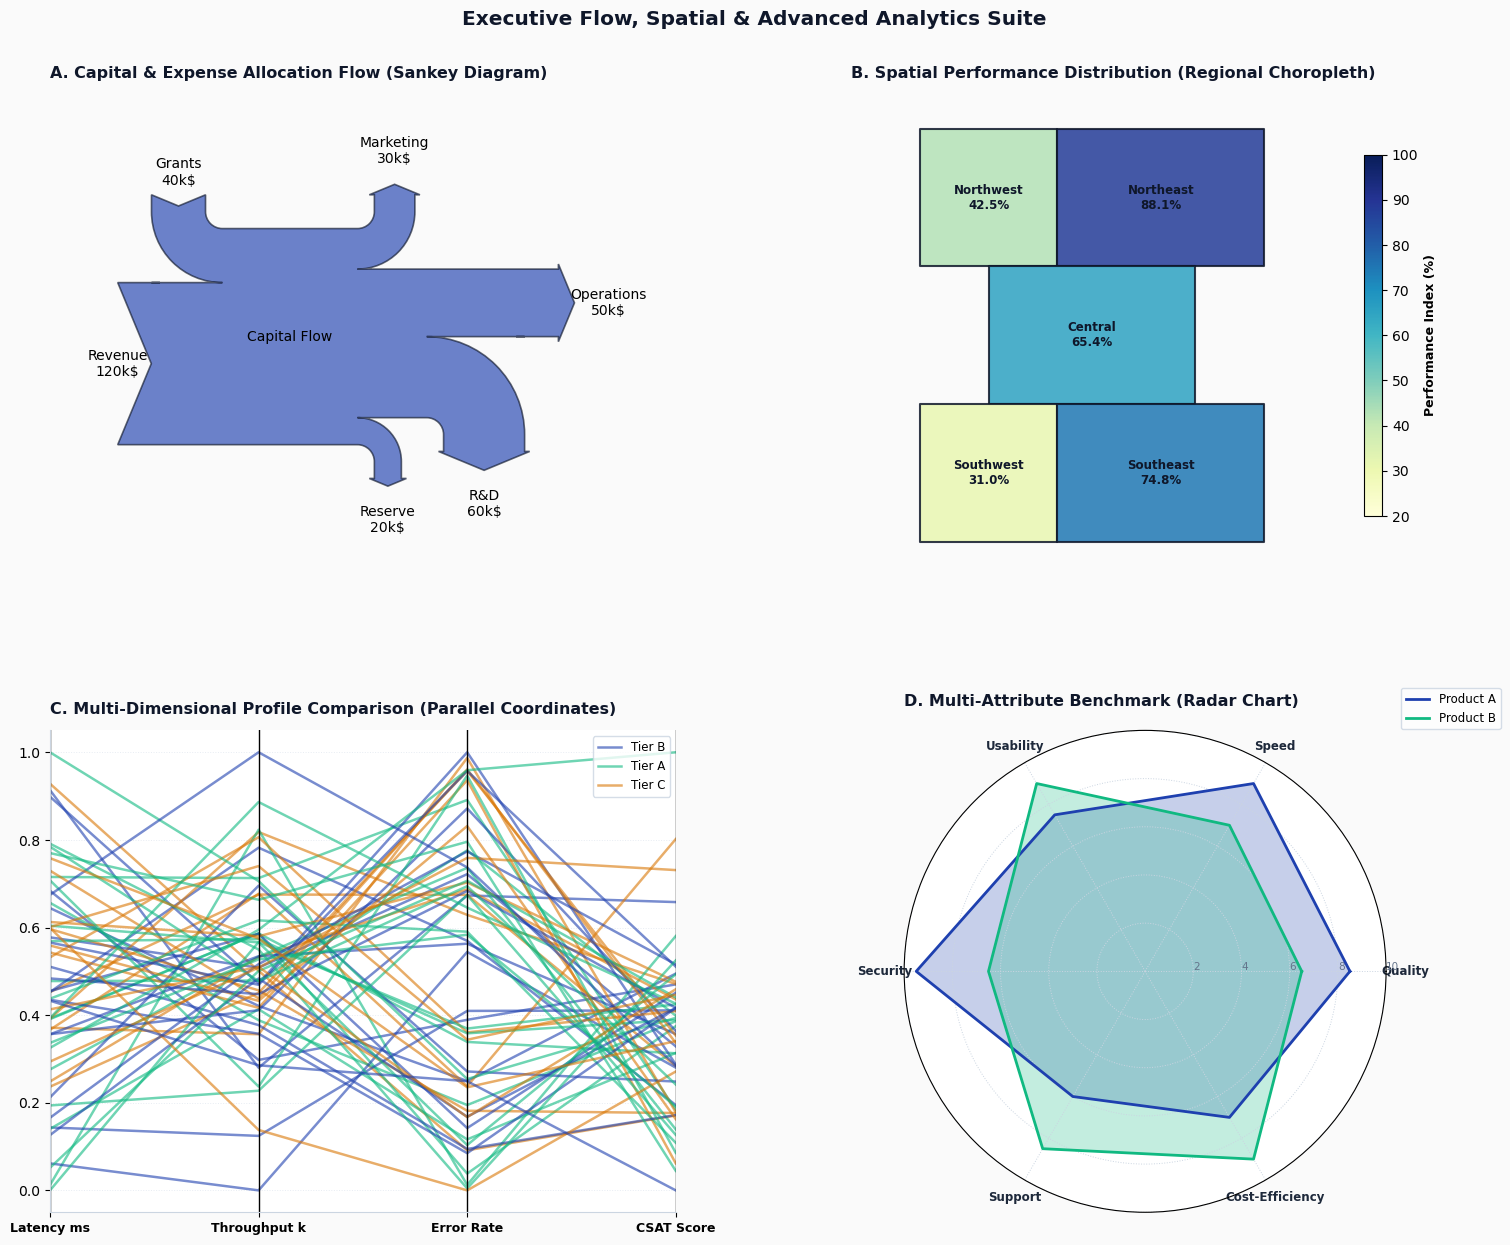

In [29]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.sankey import Sankey
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from pandas.plotting import parallel_coordinates
import numpy as np
import pandas as pd
import seaborn as sns

# ---------------------------------------------------------
# Cell 16: Flow, Spatial & Advanced Analytics Suite (05.01 - 05.04)
# ---------------------------------------------------------
np.random.seed(42)

# Palette Definitions
palette = ["#1E40AF", "#10B981", "#D97706", "#7C3AED", "#EC4899"]

# ---------------------------------------------------------
# Figure & Subplot Grid Canvas
# ---------------------------------------------------------
fig = plt.figure(figsize=(16, 13), dpi=100)
fig.patch.set_facecolor("#FAFAFA")

ax_sankey = fig.add_subplot(2, 2, 1)
ax_map = fig.add_subplot(2, 2, 2)
ax_parallel = fig.add_subplot(2, 2, 3)
ax_radar = fig.add_subplot(2, 2, 4, projection="polar")

for ax in [ax_sankey, ax_map, ax_parallel]:
    ax.set_facecolor("#FFFFFF")
ax_radar.set_facecolor("#FFFFFF")

# =========================================================
# 1. SANKEY FLOW DIAGRAM [05.01]
# =========================================================
sankey = Sankey(
    ax=ax_sankey,
    scale=0.008,
    offset=0.2,
    head_angle=135,
    format="%.0f",
    unit="k$"
)

# Flow Inputs (+) and Outputs (-)
sankey.add(
    flows=[120, 40, -50, -60, -30, -20],
    labels=["Revenue", "Grants", "Operations", "R&D", "Marketing", "Reserve"],
    orientations=[0, 1, 0, -1, 1, -1],
    pathlengths=[0.2, 0.2, 0.2, 0.2, 0.2, 0.2],
    patchlabel="Capital Flow",
    facecolor="#1E40AF",
    alpha=0.65,
    edgecolor="#0F172A",
    linewidth=1.2
)
sankey.finish()

ax_sankey.set_title("A. Capital & Expense Allocation Flow (Sankey Diagram)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_sankey.axis("off")

# =========================================================
# 2. CHOROPLETH REGIONAL MAP [05.02]
# =========================================================
# Synthetic Geographical Territory Polygons (Regional Grid Map)
regions = {
    "Northwest": np.array([[1, 4], [3, 4], [3, 6], [1, 6]]),
    "Northeast": np.array([[3, 4], [6, 4], [6, 6], [3, 6]]),
    "Central":   np.array([[2, 2], [5, 2], [5, 4], [2, 4]]),
    "Southwest": np.array([[1, 0], [3, 0], [3, 2], [1, 2]]),
    "Southeast": np.array([[3, 0], [6, 0], [6, 2], [3, 2]])
}

region_values = {"Northwest": 42.5, "Northeast": 88.1, "Central": 65.4, "Southwest": 31.0, "Southeast": 74.8}
norm = Normalize(vmin=20, vmax=100)
cmap = plt.cm.YlGnBu

patches = []
for name, coords in regions.items():
    polygon = Polygon(coords, closed=True)
    patches.append(polygon)

p = PatchCollection(patches, cmap=cmap, norm=norm, edgecolor="#0F172A", linewidth=1.5, alpha=0.85)
p.set_array(np.array(list(region_values.values())))
ax_map.add_collection(p)

for name, coords in regions.items():
    centroid = coords.mean(axis=0)
    val = region_values[name]
    ax_map.text(centroid[0], centroid[1], f"{name}\n{val:.1f}%", ha="center", va="center", fontsize=8.5, fontweight="bold", color="#0F172A")

# Fix: Set adjustable="box" to prevent aspect ratio conflict with explicit y-limits
ax_map.set_xlim(0, 7)
ax_map.set_ylim(-0.5, 6.5)
ax_map.set_aspect("equal", adjustable="box")
ax_map.axis("off")

sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar_map = fig.colorbar(sm, ax=ax_map, shrink=0.75)
cbar_map.set_label("Performance Index (%)", fontsize=9, fontweight="bold")

ax_map.set_title("B. Spatial Performance Distribution (Regional Choropleth)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)

# =========================================================
# 3. PARALLEL COORDINATES PLOT [05.03]
# =========================================================
n_samples = 60
df_parallel = pd.DataFrame({
    "Latency_ms": np.random.normal(50, 10, n_samples),
    "Throughput_k": np.random.normal(120, 20, n_samples),
    "Error_Rate": np.random.uniform(0.1, 2.5, n_samples),
    "CSAT_Score": np.random.normal(8.5, 0.8, n_samples),
    "Tier": np.random.choice(["Tier A", "Tier B", "Tier C"], size=n_samples)
})

# Min-Max Normalization for Parallel Plot comparison
numeric_cols = ["Latency_ms", "Throughput_k", "Error_Rate", "CSAT_Score"]
df_norm = df_parallel.copy()
df_norm[numeric_cols] = (df_norm[numeric_cols] - df_norm[numeric_cols].min()) / (df_norm[numeric_cols].max() - df_norm[numeric_cols].min())

parallel_coordinates(
    df_norm,
    "Tier",
    color=palette[:3],
    ax=ax_parallel,
    alpha=0.6,
    linewidth=1.8
)

ax_parallel.set_title("C. Multi-Dimensional Profile Comparison (Parallel Coordinates)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)
ax_parallel.set_xticklabels([col.replace("_", " ") for col in numeric_cols], fontsize=9, fontweight="semibold")
ax_parallel.legend(loc="upper right", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5)

# =========================================================
# 4. RADAR / SPIDER CHART [05.04]
# =========================================================
categories = ["Quality", "Speed", "Usability", "Security", "Support", "Cost-Efficiency"]
N = len(categories)

angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]  # Close the polar loop

vals_a = [8.5, 9.0, 7.5, 9.5, 6.0, 7.0]
vals_b = [6.5, 7.0, 9.0, 6.5, 8.5, 9.0]
vals_a += vals_a[:1]
vals_b += vals_b[:1]

ax_radar.plot(angles, vals_a, linewidth=2, linestyle="solid", color=palette[0], label="Product A")
ax_radar.fill(angles, vals_a, color=palette[0], alpha=0.25)

ax_radar.plot(angles, vals_b, linewidth=2, linestyle="solid", color=palette[1], label="Product B")
ax_radar.fill(angles, vals_b, color=palette[1], alpha=0.25)

ax_radar.set_xticks(angles[:-1])
ax_radar.set_xticklabels(categories, fontsize=8.5, fontweight="bold", color="#1E293B")
ax_radar.set_rlabel_position(0)
ax_radar.set_yticks([2, 4, 6, 8, 10])
ax_radar.set_yticklabels(["2", "4", "6", "8", "10"], fontsize=7.5, color="#64748B")
ax_radar.set_ylim(0, 10)

ax_radar.set_title("D. Multi-Attribute Benchmark (Radar Chart)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=18)
ax_radar.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1), frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5)

# ---------------------------------------------------------
# Global Grid Systems
# ---------------------------------------------------------
for ax in [ax_parallel]:
    ax.grid(True, linestyle=":", linewidth=0.7, color="#E2E8F0", alpha=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#CBD5E1")
    ax.spines["bottom"].set_color("#CBD5E1")

ax_radar.grid(True, linestyle=":", linewidth=0.7, color="#CBD5E1")

plt.suptitle("Executive Flow, Spatial & Advanced Analytics Suite", fontsize=14.5, fontweight="bold", color="#0F172A", y=0.985)

fig.subplots_adjust(top=0.92, bottom=0.06, left=0.06, right=0.94, hspace=0.32, wspace=0.25)
plt.show()

# 06. **Overlays, Spans & Annotations**
## 06.01. **Reference Lines & Spans** (`ax.axhline`, `ax.axvline`, `ax.axhspan`, `ax.axvspan`)
— Target benchmark markers and highlight bands.
## 06.02. **Secondary / Dual Axes** (`ax.twinx`, `ax.secondary_xaxis`)
— Multi-scale overlay charts (e.g., Revenue vs. Growth %).
## 06.03. **Inset Zoom Sub-Plot** (`ax.inset_axes`)
— Magnified sub-regions embedded inside a main chart frame.
## 06.04. **Embedded Data Table** (`ax.table`)
— Formatted summary metrics placed inside visual frames.

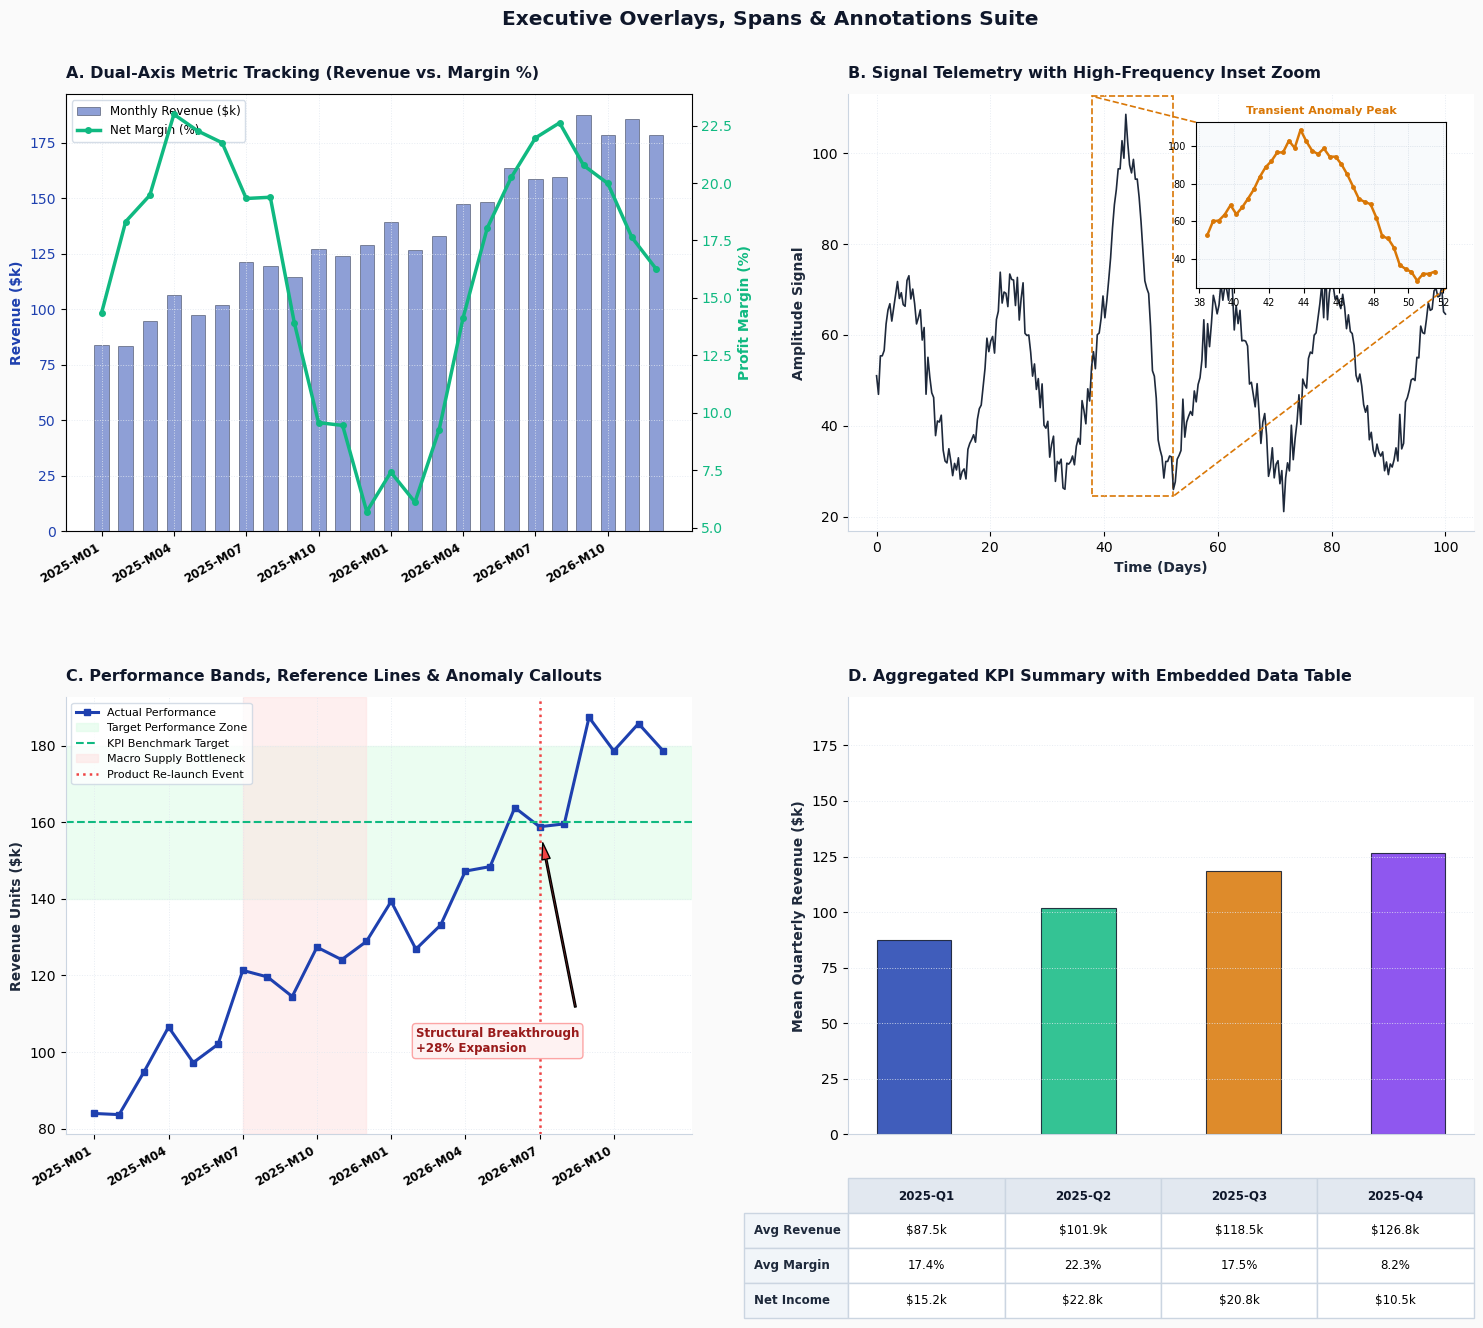

In [30]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
import numpy as np
import pandas as pd
import seaborn as sns

# ---------------------------------------------------------
# Cell 17: Overlays, Spans & Annotations Suite (06.01 - 06.04)
# ---------------------------------------------------------
np.random.seed(42)

# Palette Definitions
palette = ["#1E40AF", "#10B981", "#D97706", "#7C3AED", "#EC4899"]

# Synthetic Data Generation
months = [f"2025-M{i:02d}" for i in range(1, 13)] + [f"2026-M{i:02d}" for i in range(1, 13)]
n_months = len(months)

revenue = np.linspace(80, 190, n_months) + np.random.normal(0, 8, n_months)
margin_pct = 15 + 8 * np.sin(np.linspace(0, 3 * np.pi, n_months)) + np.random.normal(0, 1.2, n_months)

# High-frequency data for zoom plot
t_daily = np.linspace(0, 100, 300)
signal = np.sin(t_daily / 3) * 20 + np.random.normal(0, 3, 300) + 50
# Spike event in the middle
signal[120:150] += np.sin(np.linspace(0, np.pi, 30)) * 35

# ---------------------------------------------------------
# Figure & Subplot Grid Canvas
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 13), dpi=100)
fig.patch.set_facecolor("#FAFAFA")

(ax_dual, ax_zoom), (ax_spans, ax_tbl) = axes

for ax in [ax_dual, ax_zoom, ax_spans, ax_tbl]:
    ax.set_facecolor("#FFFFFF")

# =========================================================
# 1. DUAL Y-AXES OVERLAY PLOT [06.01]
# =========================================================
x_idx = np.arange(n_months)

# Primary Y-Axis: Revenue (Bar Chart)
bars = ax_dual.bar(x_idx, revenue, color="#1E40AF", alpha=0.5, width=0.6, label="Monthly Revenue ($k)", edgecolor="#0F172A", linewidth=0.6)
ax_dual.set_ylabel("Revenue ($k)", fontsize=10, fontweight="bold", color="#1E40AF")
ax_dual.tick_params(axis="y", labelcolor="#1E40AF")

# Secondary Y-Axis: Margin % (Line Chart)
ax_dual_sec = ax_dual.twinx()
line = ax_dual_sec.plot(x_idx, margin_pct, color="#10B981", linewidth=2.5, marker="o", markersize=4, label="Net Margin (%)")
ax_dual_sec.set_ylabel("Profit Margin (%)", fontsize=10, fontweight="bold", color="#10B981")
ax_dual_sec.tick_params(axis="y", labelcolor="#10B981")

# Axis Formatting & Combined Legend
ax_dual.set_xticks(x_idx[::3])
ax_dual.set_xticklabels(months[::3], rotation=30, ha="right", fontsize=8.5, fontweight="semibold")
ax_dual_sec.grid(False)  # Disable secondary grid to prevent overlap clashes

# Single unified legend
lines_1, labels_1 = ax_dual.get_legend_handles_labels()
lines_2, labels_2 = ax_dual_sec.get_legend_handles_labels()
ax_dual.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.5)

ax_dual.set_title("A. Dual-Axis Metric Tracking (Revenue vs. Margin %)", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)

# =========================================================
# 2. INSET ZOOM SUB-PLOT [06.02]
# =========================================================
ax_zoom.plot(t_daily, signal, color="#1E293B", linewidth=1.2, label="Full Telemetry Signal")
ax_zoom.set_xlabel("Time (Days)", fontsize=10, fontweight="bold", color="#1E293B")
ax_zoom.set_ylabel("Amplitude Signal", fontsize=10, fontweight="bold", color="#1E293B")

# Construct Inset Axes in Upper Right Region
ax_inset = inset_axes(ax_zoom, width="40%", height="38%", loc="upper right", borderpad=2)
ax_inset.set_facecolor("#F8FAFC")
ax_inset.plot(t_daily[115:155], signal[115:155], color="#D97706", linewidth=1.8, marker=".", markersize=5)
ax_inset.set_title("Transient Anomaly Peak", fontsize=8, fontweight="bold", color="#D97706")
ax_inset.tick_params(axis="both", labelsize=7)
ax_inset.grid(True, linestyle=":", linewidth=0.5, color="#CBD5E1")

# Connect main plot region to inset with bounding box
mark_inset(ax_zoom, ax_inset, loc1=2, loc2=4, fc="none", ec="#D97706", lw=1.2, ls="--")

ax_zoom.set_title("B. Signal Telemetry with High-Frequency Inset Zoom", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)

# =========================================================
# 3. REFERENCE SPANS & HIGHLIGHT BANDS [06.03]
# =========================================================
ax_spans.plot(x_idx, revenue, color="#1E40AF", linewidth=2.2, marker="s", markersize=4, label="Actual Performance")

# Horizontal Target Span & Vertical Event Bands
ax_spans.axhspan(140, 180, color="#DCFCE7", alpha=0.55, label="Target Performance Zone")
ax_spans.axhline(160, color="#10B981", linestyle="--", linewidth=1.5, label="KPI Benchmark Target")

ax_spans.axvspan(6, 11, color="#FEE2E2", alpha=0.55, label="Macro Supply Bottleneck")
ax_spans.axvline(18, color="#EF4444", linestyle=":", linewidth=1.8, label="Product Re-launch Event")

ax_spans.set_xticks(x_idx[::3])
ax_spans.set_xticklabels(months[::3], rotation=30, ha="right", fontsize=8.5, fontweight="semibold")
ax_spans.set_ylabel("Revenue Units ($k)", fontsize=10, fontweight="bold", color="#1E293B")

# Annotation text callout
ax_spans.annotate(
    "Structural Breakthrough\n+28% Expansion",
    xy=(18, revenue[18]),
    xytext=(13, 100),
    arrowprops=dict(facecolor="#EF4444", shrink=0.08, width=1.2, headwidth=6),
    fontsize=8.5, fontweight="bold", color="#991B1B",
    bbox=dict(boxstyle="round,pad=0.3", fc="#FEF2F2", ec="#FCA5A5", lw=1)
)

ax_spans.legend(loc="upper left", frameon=True, facecolor="#FFFFFF", edgecolor="#CBD5E1", fontsize=8.0)
ax_spans.set_title("C. Performance Bands, Reference Lines & Anomaly Callouts", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)

# =========================================================
# 4. EMBEDDED SUMMARY DATA TABLE [06.04]
# =========================================================
# Quarter-by-Quarter Summary Aggregation
q_labels = ["2025-Q1", "2025-Q2", "2025-Q3", "2025-Q4"]
q_rev = [np.mean(revenue[i*3:(i+1)*3]) for i in range(4)]
q_margin = [np.mean(margin_pct[i*3:(i+1)*3]) for i in range(4)]

# Bar Chart Visualization
bars_q = ax_tbl.bar(q_labels, q_rev, color=palette[:4], alpha=0.85, width=0.45, edgecolor="#0F172A", linewidth=0.8)
ax_tbl.set_ylabel("Mean Quarterly Revenue ($k)", fontsize=10, fontweight="bold", color="#1E293B")
ax_tbl.set_ylim(0, max(q_rev) * 1.55)

# Build Embedded Data Table Data Matrix
table_data = [
    [f"${v:.1f}k" for v in q_rev],
    [f"{m:.1f}%" for m in q_margin],
    [f"${(r * m / 100):.1f}k" for r, m in zip(q_rev, q_margin)]
]
row_headers = ["Avg Revenue", "Avg Margin", "Net Income"]

embed_table = ax_tbl.table(
    cellText=table_data,
    rowLabels=row_headers,
    colLabels=q_labels,
    loc="bottom",
    cellLoc="center",
    bbox=[0.0, -0.42, 1.0, 0.32]  # Left, Bottom, Width, Height relative to subplot
)

embed_table.auto_set_font_size(False)
embed_table.set_fontsize(8.5)

# Styling Table Cells
for (row, col), cell in embed_table.get_celld().items():
    cell.set_edgecolor("#CBD5E1")
    if row == 0:  # Header row
        cell.set_facecolor("#E2E8F0")
        cell.set_text_props(weight="bold", color="#0F172A")
    elif col == -1:  # Row labels
        cell.set_facecolor("#F1F5F9")
        cell.set_text_props(weight="bold", color="#1E293B")
    else:
        cell.set_facecolor("#FFFFFF")

# Hide X-ticks to allow clean table alignment
ax_tbl.set_xticks([])
ax_tbl.set_title("D. Aggregated KPI Summary with Embedded Data Table", fontsize=11.5, fontweight="bold", color="#0F172A", loc="left", pad=12)

# ---------------------------------------------------------
# Global Grid Systems & Canvas Polish
# ---------------------------------------------------------
for ax in [ax_dual, ax_zoom, ax_spans, ax_tbl]:
    ax.grid(True, linestyle=":", linewidth=0.7, color="#E2E8F0", alpha=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#CBD5E1")
    ax.spines["bottom"].set_color("#CBD5E1")

plt.suptitle("Executive Overlays, Spans & Annotations Suite", fontsize=14.5, fontweight="bold", color="#0F172A", y=0.985)

fig.subplots_adjust(top=0.92, bottom=0.12, left=0.06, right=0.94, hspace=0.38, wspace=0.25)
plt.show()